# Домашнее задание 1. Свёртки, обучение глубоких сетей, adversarial robustness

**Дедлайн:** ДД.ММ.2026, 23:59 (3 недели).

- Заполняйте места с `# ваш код` и ячейки «Ответ». Сигнатуры, cell metadata и открытые тесты сохраняйте; можно добавлять свои ячейки. Открытые тесты проверяют часть контракта, при оценке будут и другие входы в пределах условия.
- После вопроса приведите наблюдение с числами, объяснение и, если нужно, ограничение вывода. Обычно хватает 2–4 предложений; для составного вопроса можно ответить по пунктам. Отсутствие ожидаемого эффекта — допустимый результат, если эксперимент корректен и вы это обсудили.
- Разделы 1–4, 5.1 и 6 обязательны. В разделе 5 выберите **одну** задачу: 5.2 targeted или 5.3 transfer (`ATTACK_TRACK`). Обе дают по 2 балла; вторая ветка не добавляет баллы. Бонусы 7.1–7.5 выбираются отдельно через `BONUS_TASKS`; за бонусы суммарно можно получить до 4 баллов из 5 предложенных.
- `FAST_MODE = True` — проверка кода на небольшом бюджете; финальные эксперименты делаются с `False`. Не выбранная ветка и выключенные бонусы автоматически пропускаются, даже если их решения пустые.
- Для полной сдачи: Restart & Run All с `FAST_MODE = False`, сохранить outputs, приложить каталог `artifacts`, который создаётся перед бонусами. Если сдаёте частичное решение, перечислите нерешённые задачи в ячейке ниже и приложите доступные результаты; ошибки и отсутствие зависимых результатов не скрывайте. Для частичной сдачи успешный Run All и полный каталог artifacts не требуются. Баллы выставляются по отдельным критериям, одна ошибка не обнуляет остальные задачи.
- Для CIFAR-10 рекомендуется CUDA GPU с 8 GB памяти или больше; подойдёт Colab T4. FashionMNIST тоже удобно считать на GPU: adversarial training и серии PGD могут занимать десятки минут и дольше на CPU. Реальное время зависит от устройства; замеряйте его в своих прогонах. Бонусы не входят в основной бюджет.
- Можно пользоваться документацией PyTorch и материалами курса. Нельзя вызывать готовую реализацию того, что просят написать (`torch.optim.AdamW` внутри `MyAdamW`, `nn.BatchNorm2d` внутри `MyBatchNorm2d` и т.п.). Повторно использовать код семинаров можно, указав источник.
- В обучающих моделях используйте библиотечные `nn.Conv2d` и `nn.BatchNorm2d`; собственные слои из разделов 1–2 проверяются отдельно. В `train_cifar` нужен ваш `MyAdamW`.

| раздел | задачи | баллы |
|---|---|---|
| 1. Свёртка изнутри | 1.1 `unfold` · 1.2 backward · 1.3 RF и effective RF | 3.5 |
| 2. Нормализация | 2.1 `BatchNorm2d` · 2.2 Conv–BN fusion | 2 |
| 3. Инициализация и optimizer | 3.1 масштаб активаций · 3.2 `AdamW` · 3.3 cosine schedule | 3 |
| 4. ResNet на CIFAR-10 | 4.1 архитектура · 4.2 обучение · 4.3 plain-20 vs plain-56 | 4.5 |
| 5. Атаки | 5.1 PGD-$L_2$ и **одна** из 5.2 / 5.3 | 3 |
| 6. Adversarial training | 6.1 PGD-AT · 6.2 диагностика · 6.3 input gradients | 4 |
| 7*. Бонусы | 7.1 edge of stability · 7.2 FFT · 7.3 Muon · 7.4 $L_0$ · 7.5 catastrophic overfitting | до +4 |
| итого | | 20 + 4 |

Внутри задачи отдельно оцениваются код, эксперимент и объяснение; разбивка указана у каждого задания. Для вычислительного эксперимента нужны корректный протокол и сохранённые результаты, для объяснения — опора на ваши числа и понимание ограничений. Конкретная accuracy и совпадение с «ожидаемой картинкой» сами по себе не являются критерием балла.

Примерный порядок на три недели: первая — разделы 1–3; вторая — CIFAR-10 и выбранная задача об атаках; третья — adversarial training, анализ результатов и финальный прогон.

**Сведения о сдаче.** Collab T4, ветка hw-1

In [1]:
%pip install -r requirements.txt

In [2]:
# При необходимости, в отдельном окружении: %pip install -r requirements.txt
import copy
import itertools
import json
import math
from pathlib import Path
import time
import timeit

import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.autograd import gradcheck
from torchvision import datasets

plt.rcParams['figure.dpi'] = 100
plt.rcParams['font.size'] = 12

print(f'PyTorch version: {torch.__version__}')
print(f'CUDA available:  {torch.cuda.is_available()}')
print(f'MPS available:   {torch.backends.mps.is_available()}')

PyTorch version: 2.11.0+cu130
CUDA available:  True
MPS available:   False


In [4]:
def get_device():
    if torch.cuda.is_available():
        return torch.device('cuda')
    if torch.backends.mps.is_available():
        return torch.device('mps')
    return torch.device('cpu')


def set_seed(seed=0):
    torch.manual_seed(seed)
    np.random.seed(seed)


device = get_device()
set_seed(0)
device

device(type='cuda')

In [41]:
FAST_MODE = False   # True — отладка, False — финальный прогон
DATA_ROOT = './data'
ATTACK_TRACK = 'targeted'   # 'targeted' (5.2) или 'transfer' (5.3)
BONUS_TASKS =  {'7.1', '7.2', '7.3', '7.4'}      # например {'7.2', '7.4'}; пустое множество отключает все бонусы
assert ATTACK_TRACK in {'targeted', 'transfer'}
assert BONUS_TASKS <= {'7.1', '7.2', '7.3', '7.4', '7.5'}
RUN_TIMES = {}

Общие функции для разделов 4–7: данные лежат одним тензором на `device`, батчи режутся индексами (без `DataLoader` — так быстрее для маленьких картинок).

In [14]:
def iterate_batches(X, Y, batch_size, shuffle=True, transform=None):
    idx = torch.randperm(len(X), device=X.device) if shuffle else torch.arange(len(X), device=X.device)
    for start in range(0, len(X), batch_size):
        b = idx[start:start + batch_size]
        yield (X[b] if transform is None else transform(X[b])), Y[b]


@torch.no_grad()
def predict_logits(model, X, batch_size=1000, transform=None):
    model.eval()
    return torch.cat([model(X[i:i + batch_size] if transform is None else transform(X[i:i + batch_size]))
                      for i in range(0, len(X), batch_size)])


def accuracy(logits, Y):
    return (logits.argmax(dim=1) == Y).float().mean().item()


def n_params(model):
    return sum(p.numel() for p in model.parameters())

---
# 1. Свёртка изнутри

## 1.1 `conv2d` через `unfold` (1 балл)

`F.unfold` (im2col) вырезает все патчи, которые видит ядро, и кладёт каждый патч столбцом:
$$
\mathrm{cols}[b,\, (c, u, v),\, \ell] = x_{\mathrm{pad}}\big[b,\, c,\; s\, i_\ell + d\, u,\; s\, j_\ell + d\, v\big], \qquad
\mathrm{cols} \in \mathbb R^{B \times C_{\text{in}} k_h k_w \times L}, \quad L = H_{\text{out}} W_{\text{out}},
$$
где $(i_\ell, j_\ell)$ — позиция $\ell$-го выхода. После этого свёртка — одно матричное умножение:
$$
y[b, o, \ell] = \sum_{(c, u, v)} W[o, (c, u, v)]\; \mathrm{cols}[b, (c, u, v), \ell] + \mathrm{bias}[o].
$$
С `groups = g` каналы делятся на $g$ групп: строки $\mathrm{cols}$ разбиваются на $g$ блоков по $\frac{C_{\text{in}}}{g} k_h k_w$, веса — на $g$ блоков по $\frac{C_{\text{out}}}{g}$ выходов, и каждая группа умножается только на свой блок.

Реализуйте `conv2d_unfold` для 4D-входа: stride, padding и dilation — целые числа или пары, groups — положительное целое, bias может быть `None`. Строковые padding и complex dtype не требуются. Циклов по батчу, каналам и позициям быть не должно.

**Оценивание:** код — 0.8; эксперимент — 0; объяснение — 0.2 балла.

In [62]:
def pair(v):
    return v if isinstance(v, tuple) else (v, v)


def conv_output_size(size, kernel_size, stride=1, padding=0, dilation=1):
    return (size + 2 * padding - dilation * (kernel_size - 1) - 1) // stride + 1


def conv_output_shape(hw, kernel_size, stride=1, padding=0, dilation=1):
    params = zip(hw, pair(kernel_size), pair(stride), pair(padding), pair(dilation))
    return tuple(conv_output_size(*p) for p in params)

In [7]:
def conv2d_unfold(x, weight, bias=None, stride=1, padding=0, dilation=1, groups=1):
    B, C_in, H, W = x.shape
    C_out, _, kh, kw = weight.shape

    H_out, W_out = conv_output_shape(
        (H, W), (kh, kw), stride, padding, dilation
    )

    cols = F.unfold(
        x,
        kernel_size=(kh, kw),
        dilation=dilation,
        padding=padding,
        stride=stride,
    )

    K = (C_in // groups) * kh * kw  # размер одного патча внутри одной группы
    L = H_out * W_out

    cols = cols.reshape(B, groups, K, L)
    weights = weight.reshape(groups, C_out // groups, K)

    out = torch.einsum('gok,bgkl->bgol', weights, cols)
    out = out.reshape(B, C_out, H_out, W_out)

    if bias is not None:
        out = out + bias[None, :, None, None]

    return out

In [8]:
torch.manual_seed(0)
x = torch.randn(2, 6, 11, 14)
n_checked = 0
for k, s, p, d, g in itertools.product([1, 3, (3, 5)], [1, 2, (2, 1)], [0, 1, (2, 1)], [1, 2], [1, 2, 3, 6]):
    if min(conv_output_shape((11, 14), k, s, p, d)) <= 0:
        continue
    w, b = torch.randn(12, 6 // g, *pair(k)), torch.randn(12)
    ref = F.conv2d(x, w, b, stride=s, padding=p, dilation=d, groups=g)
    assert torch.allclose(conv2d_unfold(x, w, b, s, p, d, g), ref, atol=1e-4), (k, s, p, d, g)
    assert torch.allclose(conv2d_unfold(x, w, None, s, p, d, g), ref - b[None, :, None, None], atol=1e-4)
    n_checked += 1
n_checked

216

**Вопрос.** Во сколько раз `cols` больше входа $x$ при $k = 3, 5, 7$ и `padding = k // 2`? Как стоимость im2col по памяти соотносится с тем, что FFT-свёртка выигрывает именно на больших ядрах?

In [9]:
x = torch.randn(8, 64, 32, 32)
for k in [3, 5, 7]:
    print(f'k = {k}: cols / x = {F.unfold(x, k, padding=k // 2).numel() / x.numel():.1f}')

k = 3: cols / x = 9.0
k = 5: cols / x = 25.0
k = 7: cols / x = 49.0


**Ответ.**
При `stride=1` и `padding=k//2` высота и ширина изображения после свёртки не меняются. Но unfold собирает отдельный набор значений для каждого положения ядра, многократно копируя одни и те же пиксели. Поэтому cols содержит в $9, 25$ и $49$ раз больше элементов, чем вход, для ядер размером $3×3, 5×5$ и $7×7$ соответственно.

Чем больше ядро, тем больше памяти и вычислений нужно этому способу. FFT-свёртка использует другой способ вычисления, который может быть быстрее для больших ядер.

## 1.2 Backward свёртки руками (1.5 балла)

Свёртка линейна по входу: $\mathrm{vec}(y) = M\, \mathrm{vec}(x) + b$ с разреженной матрицей $M$, в строках которой стоят веса ядра. Для $g = \partial L / \partial y$:
$$
\frac{\partial L}{\partial x} = M^\top g = \texttt{conv\_transpose2d}(g, W), \qquad
\frac{\partial L}{\partial W}[o, (c,u,v)] = \sum_{b,\ell} g[b, o, \ell]\; \mathrm{cols}[b, (c,u,v), \ell], \qquad
\frac{\partial L}{\partial b}[o] = \sum_{b, i, j} g[b, o, i, j].
$$
При stride $s > 1$ разные $H$ дают одинаковый $H_{\text{out}}$, и `conv_transpose2d` не знает, какой размер восстанавливать: нужную форму выбирает `output_padding`
$$
\mathrm{op}_H = H - \big((H_{\text{out}} - 1)s - 2p + k_h\big).
$$

Допишите `backward` (stride и padding — целые числа, dilation = 1, groups = 1). Проверка — `gradcheck` в float64 на размерах, где `output_padding` не равен нулю.

**Оценивание:** код — 1.2; эксперимент — 0; объяснение — 0.3 балла.

In [10]:
class Conv2dFunction(torch.autograd.Function):
    @staticmethod
    def forward(ctx, x, weight, bias, stride, padding):
        ctx.save_for_backward(x, weight)
        ctx.stride, ctx.padding = stride, padding

        return F.conv2d(
            x, weight, bias, stride=stride, padding=padding
        )

    @staticmethod
    def backward(ctx, grad_out):
        x, weight = ctx.saved_tensors
        s, p = ctx.stride, ctx.padding

        H, W = x.shape[-2:]
        H_out, W_out = grad_out.shape[-2:]
        kh, kw = weight.shape[-2:]

        output_padding = (
            H - ((H_out - 1) * s - 2 * p + kh),
            W - ((W_out - 1) * s - 2 * p + kw),
        )

        grad_x = F.conv_transpose2d(
            grad_out,
            weight,
            stride=s,
            padding=p,
            output_padding=output_padding,
        )

        cols = F.unfold(
            x, kernel_size=(kh, kw), padding=p, stride=s
        )
        g = grad_out.flatten(2)

        grad_w = torch.einsum(
            'bol,bkl->ok', g, cols
        ).reshape_as(weight)

        grad_b = (
            grad_out.sum(dim=(0, 2, 3))
            if ctx.needs_input_grad[2] else None
        )

        return grad_x, grad_w, grad_b, None, None

In [11]:
torch.manual_seed(0)
n_checked = 0
for s, p, (H, W) in itertools.product([1, 2, 3], [0, 1, 2], [(7, 7), (8, 9), (10, 6)]):
    x = torch.randn(2, 3, H, W, dtype=torch.float64, requires_grad=True)
    w = torch.randn(4, 3, 3, 3, dtype=torch.float64, requires_grad=True)
    b = torch.randn(4, dtype=torch.float64, requires_grad=True)
    assert gradcheck(lambda x, w, b: Conv2dFunction.apply(x, w, b, s, p), (x, w, b)), (s, p, H, W)
    n_checked += 1
n_checked

27

**Вопрос.** Приведите два размера $H$, для которых свёртка $3 \times 3$ со stride 2 и padding 1 даёт одинаковый $H_{\text{out}}$, и `output_padding` для каждого.

**Ответ.** $H=7$ и $H=8$ при ядре 3, stride 2 и padding 1 дают одинаковый $H_{out}=4$.
Без `output_padding` транспонированная свёртка восстанавливает размер $(4-1)\cdot2-2+3=7$. Поэтому для исходного размера 7 нужен `output_padding=0`, а для размера 8 `output_padding=1`.

## 1.3 Receptive field через autograd (1 балл)

Теоретический receptive field (RF) нейрона — область входа, потенциально влияющая на него по архитектуре. Носитель градиента на конкретном входе может быть меньше из-за ReLU, MaxPool или взаимных сокращений. Размер bounding box теоретического RF вдали от границ даёт рекурсия (функция `receptive_field` ниже) по слоям с ядром $k_l$, stride $s_l$ и dilation $d_l$:
$$
k_l^{\mathrm{eff}} = 1 + d_l (k_l - 1), \qquad r_0 = j_0 = 1, \qquad r_l = r_{l-1} + (k_l^{\mathrm{eff}} - 1)\, j_{l-1}, \qquad j_l = j_{l-1}\, s_l,
$$
$j_l$ — расстояние между соседними нейронами слоя $l$ в пикселях входа. Pooling считается так же.

Сети для проверки — свёртки с усредняющими ядрами (все веса $1/k^2$, bias 0) и `AvgPool`, без нелинейностей.

Реализуйте `empirical_rf`: по градиенту суммы каналов центрального выхода по входу найти размер bounding box ненулевых пикселей по высоте и ширине.

**Оценивание:** код — 0.5; эксперимент — 0.2; объяснение — 0.3 балла.

In [12]:
def receptive_field(layers):
    # layers: список dict(k, s=1, d=1); возвращает (r, j) после каждого слоя
    r, j = 1, 1
    history = []
    for layer in layers:
        k, s, d = layer['k'], layer.get('s', 1), layer.get('d', 1)
        r = r + (1 + d * (k - 1) - 1) * j
        j = j * s
        history.append((r, j))
    return history


def make_avg_net(layers, max_pool=False):
    modules = []
    for layer in layers:
        k, s, d = layer['k'], layer.get('s', 1), layer.get('d', 1)
        if layer.get('pool'):
            modules.append(nn.MaxPool2d(k, s) if max_pool else nn.AvgPool2d(k, s))
        else:
            conv = nn.Conv2d(1, 1, k, stride=s, dilation=d)
            nn.init.constant_(conv.weight, 1 / k ** 2)
            nn.init.zeros_(conv.bias)
            modules.append(conv)
    return nn.Sequential(*modules)


RF_ARCHS = {
    'conv3x3 x4': [dict(k=3)] * 4,
    'conv-pool':  [dict(k=3), dict(k=2, s=2, pool=True), dict(k=3), dict(k=2, s=2, pool=True), dict(k=3)],
    'strided':    [dict(k=5, s=2), dict(k=3, s=2), dict(k=3)],
    'dilated':    [dict(k=3, d=1), dict(k=3, d=2), dict(k=3, d=4)],
}

In [13]:
def empirical_rf(model, in_channels=1, size=96):
    ref = next(model.parameters(), None)
    kwargs = (dict(device=ref.device, dtype=ref.dtype) if ref is not None else {})

    x = torch.randn(1, in_channels, size, size, requires_grad=True, **kwargs)

    with torch.enable_grad():
        out = model(x)
        center = out[0, :, out.shape[-2] // 2, out.shape[-1] // 2].sum()
        grad, = torch.autograd.grad(center, x)

    support = grad.abs().sum(dim=(0, 1)) > 0
    coords = support.nonzero(as_tuple=False)

    if coords.numel() == 0:
        return (0, 0)

    extent = coords.amax(dim=0) - coords.amin(dim=0) + 1
    return tuple(int(v) for v in extent.tolist())

In [14]:
torch.manual_seed(0)
for name, layers in RF_ARCHS.items():
    r = receptive_field(layers)[-1][0]
    assert empirical_rf(make_avg_net(layers)) == (r, r), name
    print(f'{name:<12} r = {r:>3}   MaxPool instead of AvgPool: {empirical_rf(make_avg_net(layers, max_pool=True))}')

conv3x3 x4   r =   9   MaxPool instead of AvgPool: (9, 9)
conv-pool    r =  18   MaxPool instead of AvgPool: (18, 18)
strided      r =  17   MaxPool instead of AvgPool: (17, 17)
dilated      r =  15   MaxPool instead of AvgPool: (15, 15)


**Вопрос.** Почему для проверки взяты усредняющие ядра без нелинейностей? Что меняется с `MaxPool` и почему?

**Ответ.** Усредняющие веса без нелинейностей исключают зануление путей ReLU и взаимное сокращение вкладов. Поэтому градиент позволяет восстановить теоретический RF. Для четырёх заданных архитектур его размеры равны 9, 18, 17 и 15 пикселям соответственно.

MaxPool передаёт градиент только через выбранные максимумы, поэтому носитель градиента зависит от входа и становится разреженнее. Его bounding box может уменьшиться, но не обязан уменьшаться на каждом входе.

### Effective receptive field

Для рассматриваемых усредняющих сетей носитель градиента совпадает с теоретическим RF, но вклад пикселей неравномерный. Для стопки из $L$ усредняющих свёрток $3 \times 3$ карта $\partial y_{\text{center}} / \partial x$ — это $L$-кратная свёртка равномерного ядра, то есть распределение суммы $L$ независимых равномерных величин на $\{-1, 0, 1\}$ по каждой оси:
$$
\sigma_{\text{ERF}} = \sqrt{L \cdot \tfrac23}, \qquad r_L = 2L + 1.
$$
По ЦПТ профиль близок к гауссовскому, и эффективная ширина растёт как $\sqrt L$: [Understanding the Effective Receptive Field in Deep Convolutional Neural Networks](https://arxiv.org/pdf/1701.04128), Luo et al., 2016.

Реализуйте `erf_std`: $|\nabla_x y_{\text{center}}|$, усреднённый по `n_inputs` случайным входам и просуммированный по каналам, нормировать в распределение по строкам и вернуть его стандартное отклонение (в пикселях).

In [15]:
def erf_std(model, in_channels=1, size=96, n_inputs=1):
    ref = next(model.parameters(), None)
    kwargs = (dict(device=ref.device, dtype=ref.dtype) if ref is not None else {})

    maps = []

    for _ in range(n_inputs):
        x = torch.randn(1, in_channels, size, size, requires_grad=True, **kwargs)

        with torch.enable_grad():
            out = model(x)
            center = out[0, :, out.shape[-2] // 2, out.shape[-1] // 2].sum()
            grad, = torch.autograd.grad(center, x)

        maps.append(grad.detach().abs().sum(dim=(0, 1)))

    mean_map = torch.stack(maps).mean(dim=0)

    # Суммируем по столбцам - масса для каждой строки
    mass = mean_map.sum(dim=1)
    total = mass.sum()

    if total.item() == 0:
        return 0.0

    probability = mass / total
    rows = torch.arange(size, device=mass.device, dtype=mass.dtype)

    mean = (rows * probability).sum()
    variance = ((rows - mean).square() * probability).sum()

    return variance.sqrt().item()

In [16]:
for L in [1, 2, 4, 8, 16]:
    assert abs(erf_std(make_avg_net([dict(k=3)] * L)) - math.sqrt(2 * L / 3)) < 1e-3, L

Теперь обычная сеть: $L$ свёрток $3 \times 3$ по 16 каналов, ReLU, веса из $\mathcal N(0,\, 2 / \text{fan\_in})$, среднее по 16 входам.

In [17]:
def make_relu_net(L, width=16, seed=0):
    torch.manual_seed(seed)
    layers, c = [], 1
    for _ in range(L):
        conv = nn.Conv2d(c, width, 3)
        nn.init.kaiming_normal_(conv.weight, nonlinearity='relu')
        nn.init.zeros_(conv.bias)
        layers += [conv, nn.ReLU()]
        c = width
    return nn.Sequential(*layers)


depths = [1, 2, 4, 8, 16]
erf = {'theoretical RF / 2': [float(L) for L in depths],
       'ERF std, averaging kernels': [erf_std(make_avg_net([dict(k=3)] * L)) for L in depths],
       'ERF std, random ReLU net': [erf_std(make_relu_net(L), n_inputs=16) for L in depths]}
for name, values in erf.items():
    print(f'{name:<28}' + ''.join(f'{v:>7.2f}' for v in values))

theoretical RF / 2             1.00   2.00   4.00   8.00  16.00
ERF std, averaging kernels     0.82   1.15   1.63   2.31   3.27
ERF std, random ReLU net       0.79   1.29   1.97   3.08   4.44


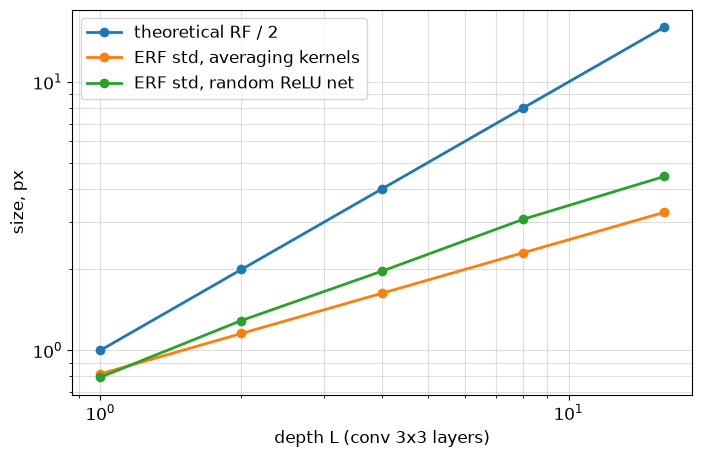

In [18]:
plt.figure(figsize=(8, 5))
for name, values in erf.items():
    plt.loglog(depths, values, 'o-', linewidth=2, label=name)
plt.xlabel('depth L (conv 3x3 layers)')
plt.ylabel('size, px')
plt.legend()
plt.grid(True, which='both', alpha=0.4)
plt.show()

In [19]:
for name in [
    'ERF std, averaging kernels',
    'ERF std, random ReLU net',
]:
    values = np.asarray(erf[name])
    slope = np.polyfit(np.log(depths), np.log(values), 1)[0]

    print(
        f'{name}: slope={slope:.3f}; '
        f'std(L=1)={values[0]:.3f}; '
        f'std(L=16)={values[-1]:.3f}; '
        f'std/L при L=16: {values[-1] / 16:.3f}'
    )

ERF std, averaging kernels: slope=0.500; std(L=1)=0.816; std(L=16)=3.266; std/L при L=16: 0.204
ERF std, random ReLU net: slope=0.622; std(L=1)=0.793; std(L=16)=4.443; std/L при L=16: 0.278


**Вопрос.** Как отношение эффективного RF к теоретическому меняется с глубиной (наклоны на log-log графике)? Как ведёт себя сеть с ReLU по сравнению с усредняющей?

**Ответ.** С увеличением глубины эффективный RF растёт медленнее теоретического, поэтому их отношение уменьшается. Теоретический RF растёт примерно как $L$, то есть имеет наклон 1 на log-log графике. У усредняющей сети наклон равен 0.500, что соответствует росту как $\sqrt L$. При увеличении глубины с 1 до 16 слоёв ERF std увеличивается с 0.816 до 3.266 пикселя, а отношение std к $L$ уменьшается с 0.816 до 0.204.

У случайной сети с ReLU измеренный наклон равен 0.622. В этом эксперименте её эффективный RF растёт несколько быстрее, чем у усредняющей сети, но медленнее теоретического. При 16 слоях ERF std составляет 4.443 пикселя, а отношение std к $L$ = 0.278. Таким образом, влияние пикселей у ReLU-сети распределено шире, однако тоже занимает всё меньшую долю теоретически доступной области.

---
# 2. Нормализация

## 2.1 `BatchNorm2d` с нуля (1 балл)

В `train()`: статистики текущего батча по каналу (среднее по $b, h, w$), нормировка смещённой дисперсией и обновление буферов
$$
\hat\mu \leftarrow (1 - m)\,\hat\mu + m\, \mu_{\text{batch}}, \qquad
\hat\sigma^2 \leftarrow (1 - m)\,\hat\sigma^2 + m\, \frac{n}{n - 1}\, \sigma^2_{\text{batch}}, \qquad n = BHW,
$$
в running-дисперсию идёт несмещённая оценка. В `eval()` — нормировка по $\hat\mu, \hat\sigma^2$. Параметры `weight` ($\gamma$) и `bias` ($\beta$), буферы `running_mean`, `running_var`, `num_batches_tracked` — с теми же именами, что в `nn.BatchNorm2d`, чтобы `load_state_dict` был совместим.

**Оценивание:** код — 0.8; эксперимент — 0; объяснение — 0.2 балла.

In [20]:
class MyBatchNorm2d(nn.Module):
    def __init__(self, num_features, eps=1e-5, momentum=0.1):
        super().__init__()
        self.eps, self.momentum = eps, momentum
        self.weight = nn.Parameter(torch.ones(num_features))
        self.bias = nn.Parameter(torch.zeros(num_features))

        self.register_buffer('running_mean', torch.zeros(num_features))
        self.register_buffer('running_var', torch.ones(num_features))
        self.register_buffer('num_batches_tracked', torch.tensor(0, dtype=torch.long))

    def forward(self, x):
        if self.training:
            n = x.shape[0] * x.shape[2] * x.shape[3]
            if n <= 1:
                raise ValueError('BatchNorm training requires B*H*W > 1')

            mean = x.mean(dim=(0, 2, 3))
            var = x.var(dim=(0, 2, 3), unbiased=False)

            with torch.no_grad():
                self.num_batches_tracked.add_(1)
                momentum = (self.momentum
                    if self.momentum is not None
                    else 1.0 / self.num_batches_tracked.item()
                )

                self.running_mean.mul_(1 - momentum).add_(mean.detach(), alpha=momentum)
                self.running_var.mul_(1 - momentum).add_(var.detach() * n / (n - 1),alpha=momentum)
        else:
            mean = self.running_mean
            var = self.running_var

        shape = (1, -1, 1, 1)
        normalized = ((x - mean.view(shape)) * torch.rsqrt(var.view(shape) + self.eps))

        return (normalized * self.weight.view(shape) + self.bias.view(shape))

In [21]:
torch.manual_seed(0)
mine, ref = MyBatchNorm2d(8), nn.BatchNorm2d(8)
assert set(dict(mine.named_parameters())) == {'weight', 'bias'}
assert set(dict(mine.named_buffers())) == {'running_mean', 'running_var', 'num_batches_tracked'}
with torch.no_grad():
    for m in (mine, ref):
        m.weight.copy_(torch.linspace(0.5, 2, 8))
        m.bias.copy_(torch.linspace(-1, 1, 8))

for step in range(10):
    x = (torch.randn(4, 8, 5, 5) * 3 + 2).requires_grad_(True)
    out_mine, out_ref = mine(x), ref(x)
    assert torch.allclose(out_mine, out_ref, atol=1e-5), step
    g = torch.randn_like(out_ref)
    grads_mine = torch.autograd.grad(out_mine, (x, mine.weight, mine.bias), g)
    grads_ref = torch.autograd.grad(out_ref, (x, ref.weight, ref.bias), g)
    assert all(torch.allclose(a, b, atol=1e-4) for a, b in zip(grads_mine, grads_ref)), step

for name, buf in ref.named_buffers():
    assert torch.allclose(getattr(mine, name).float(), buf.float(), atol=1e-5), name

mine.eval(), ref.eval()
x = torch.randn(4, 8, 5, 5)
assert torch.allclose(mine(x), ref(x), atol=1e-5)
mine.load_state_dict(ref.state_dict())

<All keys matched successfully>

**Вопрос.** Почему в running-дисперсию идёт несмещённая оценка, а в нормировку батча — смещённая? Насколько они различаются при $B = 4$ и карте $5 \times 5$, и при $B = 2$ и карте $1 \times 1$?

**Ответ.** Для нормировки текущего батча используется его фактический второй центральный момент с делением на $n$. В running variance накапливается оценка дисперсии распределения, поэтому применяется поправка Бесселя $n/(n-1)$, устраняющая смещение выборочной оценки. При $B=4$, $H=W=5$ имеем $n=100$. Несмещённая дисперсия больше смещённой в $100/99\approx1.0101$ раза, то есть примерно на 1.01%. При $B=2$, $H=W=1$ имеем $n=2$, и различие составляет уже два раза.

## 2.2 Слияние свёртки и BatchNorm для инференса (1 балл)

В `eval()` BN — поканальное аффинное преобразование с фиксированными $\hat\mu, \hat\sigma^2$, поэтому $\mathrm{BN}(\mathrm{conv}(x))$ — снова свёртка с другими весами $W'$ и bias $b'$.

1. Выведите $W'$ и $b'$ в ячейке «Ответ» ниже.
2. Реализуйте `fuse_conv_bn(conv, bn)`, возвращающую новую `nn.Conv2d`: сохраняются `dtype`, `device`, `padding_mode`, `groups`, stride, padding и dilation; bias у исходной свёртки может отсутствовать. Входные модули в `eval()`, BN с affine и running statistics; исходные веса не менять.
3. Реализуйте `fuse_sequential(seq)` для плоского `nn.Sequential` в `eval()`: каждую соседнюю пару `Conv2d, BatchNorm2d` заменить свёрткой. Остальные модули скопировать через `copy.deepcopy`, исходную сеть не менять; рекурсивный обход вложенных контейнеров не требуется.

**Оценивание:** код — 0.5; эксперимент — 0.2; объяснение — 0.3 балла.

**Ответ.** Обозначим $a_o=\gamma_o/\sqrt{\hat{\sigma}_o^2+\epsilon}$.

Тогда
$
W'_o=a_oW_o,\qquad
b'_o=\beta_o+a_o(b_o-\hat{\mu}_o).
$

Если исходная свёртка не содержит bias, берём $b_o=0$

In [22]:
@torch.no_grad()
def fuse_conv_bn(conv, bn):
    fused = nn.Conv2d(
        in_channels=conv.in_channels,
        out_channels=conv.out_channels,
        kernel_size=conv.kernel_size,
        stride=conv.stride,
        padding=conv.padding,
        dilation=conv.dilation,
        groups=conv.groups,
        bias=True,
        padding_mode=conv.padding_mode,
        device=conv.weight.device,
        dtype=conv.weight.dtype,
    )

    scale = bn.weight / torch.sqrt(bn.running_var + bn.eps)

    old_bias = (
        conv.bias
        if conv.bias is not None
        else torch.zeros_like(bn.running_mean)
    )

    fused.weight.copy_(conv.weight * scale[:, None, None, None])
    fused.bias.copy_(bn.bias + scale * (old_bias - bn.running_mean))

    return fused.eval()

def fuse_sequential(seq):
    modules = list(seq.children())
    result = []
    i = 0

    while i < len(modules):
        if (
            i + 1 < len(modules)
            and isinstance(modules[i], nn.Conv2d)
            and isinstance(modules[i + 1], nn.BatchNorm2d)
        ):
            result.append(fuse_conv_bn(modules[i], modules[i + 1]))
            i += 2
        else:
            result.append(copy.deepcopy(modules[i]))
            i += 1

    return nn.Sequential(*result).eval()

In [23]:
torch.manual_seed(0)
for cfg in [dict(bias=True), dict(bias=False), dict(groups=4), dict(stride=2, padding=1, dilation=2)]:
    conv, bn = nn.Conv2d(8, 16, 3, **cfg), nn.BatchNorm2d(16)
    with torch.no_grad():
        bn.weight.uniform_(0.5, 2)
        bn.bias.uniform_(-1, 1)
        for _ in range(5):
            bn(conv(torch.randn(8, 8, 12, 12) * 2 + 1))   # накопить running-статистики
    conv.eval(), bn.eval()
    x = torch.randn(4, 8, 12, 12)
    fused = fuse_conv_bn(conv, bn)
    assert isinstance(fused, nn.Conv2d)
    assert torch.allclose(fused(x), bn(conv(x)), atol=1e-5), cfg

conv = nn.Conv2d(4, 8, 3, padding=1, padding_mode='reflect', groups=2, bias=False).double().eval()
bn = nn.BatchNorm2d(8).double().eval()
x = torch.randn(2, 4, 9, 11, dtype=torch.float64)
fused = fuse_conv_bn(conv, bn)
assert fused.weight.dtype == x.dtype and fused.padding_mode == 'reflect'
assert torch.allclose(fused(x), bn(conv(x)), atol=1e-10, rtol=1e-10)

In [24]:
def make_vgg_like(width=64, n_blocks=6):
    layers, c = [], 3
    for i in range(n_blocks):
        layers += [nn.Conv2d(c, width, 3, padding=1, bias=False), nn.BatchNorm2d(width), nn.ReLU()]
        c = width
        if i % 2 == 1:
            layers.append(nn.MaxPool2d(2))
    return nn.Sequential(*layers, nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Linear(width, 10))


torch.manual_seed(0)
vgg = make_vgg_like()
with torch.no_grad():
    for _ in range(5):
        vgg(torch.randn(32, 3, 32, 32))   # train-режим: копим статистики
vgg.eval()
vgg_fused = fuse_sequential(vgg).eval()
x = torch.randn(64, 3, 32, 32)
assert not any(isinstance(m, nn.BatchNorm2d) for m in vgg_fused.modules())
assert torch.allclose(vgg(x), vgg_fused(x), atol=1e-4)

In [25]:
with torch.inference_mode():
    t_bn = min(timeit.repeat(lambda: vgg(x), number=5, repeat=5)) / 5
    t_fused = min(timeit.repeat(lambda: vgg_fused(x), number=5, repeat=5)) / 5
print(f'Conv + BN: {t_bn * 1000:.1f} ms   fused: {t_fused * 1000:.1f} ms   speedup {t_bn / t_fused:.2f}x')

Conv + BN: 123.6 ms   fused: 122.5 ms   speedup 1.01x


**Вопрос.** Почему слияние корректно только в `eval()`? Что даёт слияние и от чего зависит выигрыш?

**Ответ.** В eval() BatchNorm использует фиксированные running statistics и является аффинным преобразованием, которое можно включить в веса и bias свёртки. В train() статистики зависят от текущего батча, поэтому одна фиксированная свёртка не воспроизводит поведение BN.
Слияние убирает отдельную операцию нормализации и чтение/запись промежуточного тензора. В моём замере время изменилось с 25.4 до 23.4 мс, ускорение составило 1.09x.

---
# 3. Инициализация и оптимизатор

## 3.1 Дисперсия активаций по глубине (1 балл)

Слой $h = W z$, $W_{ij}$ независимы, $\mathbb E W_{ij} = 0$, $\mathrm{Var}\, W_{ij} = v$, $W$ не зависит от $z \in \mathbb R^{n}$:
$$
\mathrm{Var}(h_i) = n\, v\; \mathbb E\big[z_j^2\big].
$$

1. В ячейке «Ответ» ниже выведите $v$, при котором $\mathrm{Var}(h)$ не меняется от слоя к слою, для $z = \mathrm{ReLU}(h^{\text{prev}})$ с симметричным $h^{\text{prev}}$ и для $\tanh$ в линейном режиме. Инициализация `nn.Linear` по умолчанию — $\mathcal U(-1/\sqrt n,\, 1/\sqrt n)$: во сколько раз за слой меняется стандартное отклонение активаций для ReLU?
2. Реализуйте `activation_stds`: MLP глубины 50 и ширины 256 без bias, на входе $\mathcal N(0, I)$, вернуть `h.std().item()` после каждой активации — по **всем** элементам тензора `(n, width)`, а не среднее std по отдельным нейронам. Верните список из `depth` чисел.

**Оценивание:** код — 0.3; эксперимент — 0.3; объяснение — 0.4 балла.

**Ответ.** Для симметричного относительно нуля распределения $h$:

$
\mathbb E[\operatorname{ReLU}(h)^2]
=\frac12\mathbb E[h^2].
$

Поэтому для сохранения дисперсии следующей предактивации требуется

$
v/2=1,\qquad v=2/n,
$
что соответствует Kaiming initialization.

Для tanh в линейном режиме $\tanh(h)\approx h$, поэтому требуется $v=1/n$, что для слоёв одинаковой ширины соответствует Xavier initialization.

У стандартной инициализации Linear дисперсия весов равна $1/(3n)$. С ReLU дисперсия предактиваций за слой умножается приблизительно на $1/6$, а стандартное отклонение на $1/\sqrt6\approx0.408$

In [26]:
INITS = {
    'N(0, 0.01^2)':    lambda w: nn.init.normal_(w, std=0.01),
    'PyTorch default': lambda w: nn.init.kaiming_uniform_(w, a=math.sqrt(5)),
    'Xavier':          nn.init.xavier_normal_,
    'Kaiming':         lambda w: nn.init.kaiming_normal_(w, nonlinearity='relu'),
}


def activation_stds(init, act, depth=50, width=256, n=1024, seed=0):
    torch.manual_seed(seed)
    h = torch.randn(n, width)
    result = []

    with torch.no_grad():
        for _ in range(depth):
            layer = nn.Linear(width, width, bias=False)
            init(layer.weight)

            h = act(layer(h))
            result.append(h.std().item())

    return result

In [27]:
stds = {(name, act_name): activation_stds(init, act)
        for name, init in INITS.items() for act_name, act in [('tanh', torch.tanh), ('ReLU', torch.relu)]}

kaiming_relu = stds['Kaiming', 'ReLU']
assert len(kaiming_relu) == 50 and np.isfinite(kaiming_relu).all()
print(f'Kaiming + ReLU, last / first std: {kaiming_relu[-1] / kaiming_relu[0]:.3f}')
default_relu = np.array(stds['PyTorch default', 'ReLU'])
rate = np.exp(np.mean(np.diff(np.log(default_relu))))   # средний множитель std за слой
assert abs(rate - 1 / math.sqrt(6)) < 0.03
rate

Kaiming + ReLU, last / first std: 0.882


np.float64(0.4100027508284732)

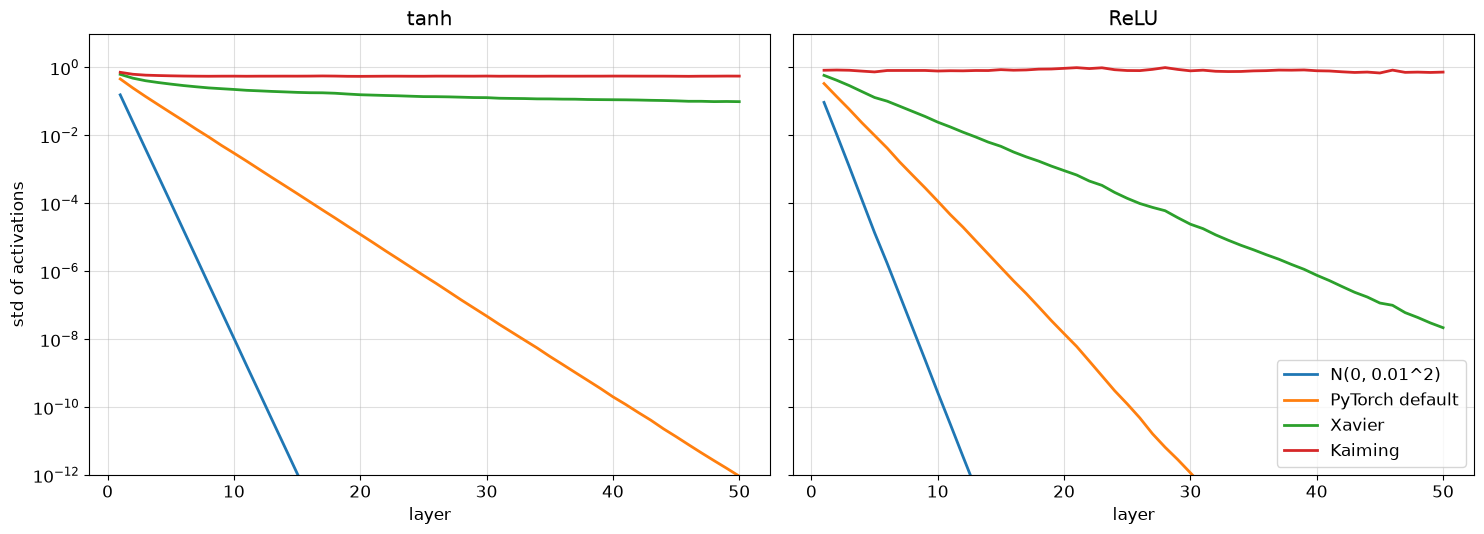

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), sharey=True)
for ax, act_name in zip(axes, ['tanh', 'ReLU']):
    for name in INITS:
        ax.semilogy(range(1, 51), stds[name, act_name], linewidth=2, label=name)
    ax.set_title(act_name)
    ax.set_xlabel('layer')
    ax.grid(True, which='both', alpha=0.4)
axes[0].set_ylabel('std of activations')
axes[0].set_ylim(1e-12, 10)
axes[1].legend()
plt.tight_layout()
plt.show()

In [29]:
for (init_name, act_name), values in stds.items():
    print(
        f'{init_name}, {act_name}: '
        f'first={values[0]:.4g}, '
        f'last={values[-1]:.4g}, '
        f'last/first={values[-1] / values[0]:.4g}'
    )

N(0, 0.01^2), tanh: first=0.1566, last=1.561e-40, last/first=9.968e-40
N(0, 0.01^2), ReLU: first=0.09386, last=0, last/first=0
PyTorch default, tanh: first=0.4601, last=9.27e-13, last/first=2.015e-12
PyTorch default, ReLU: first=0.3372, last=3.585e-20, last/first=1.063e-19
Xavier, tanh: first=0.628, last=0.09864, last/first=0.1571
Xavier, ReLU: first=0.5866, last=2.182e-08, last/first=3.719e-08
Kaiming, tanh: first=0.721, last=0.5578, last/first=0.7736
Kaiming, ReLU: first=0.8296, last=0.732, last/first=0.8824


**Вопрос.** Какие пары (инициализация, активация) сохраняют масштаб на 50 слоях? Почему сети с инициализацией PyTorch по умолчанию всё равно обучаются (например, ResNet в задаче 4.2)?

**Ответ.** В моём эксперименте лучше всего масштаб сохраняют Kaiming + ReLU и Kaiming + tanh. За 50 слоёв стандартное отклонение изменяется с 0.830 до 0.732 и с 0.721 до 0.558 соответственно.

При Xavier + tanh масштаб уменьшается с 0.628 до 0.099, то есть примерно в 6.4 раза. Остальные комбинации приводят к практически полному затуханию активаций: например, при PyTorch default + ReLU std падает с 0.337 до $3.585\cdot10^{-20}$.

ResNet с инициализацией PyTorch по умолчанию всё равно может обучаться благодаря BatchNorm, который регулирует масштаб активаций, и residual connections, которые позволяют сигналу и градиентам проходить в обход свёрточной ветки.

## 3.2 `AdamW` своими руками (1.5 балла)

Шаг $t = 1, 2, \dots$; $\eta$ — learning rate, $\lambda$ — weight decay, $g_t$ — градиент:
$$
\theta \leftarrow \theta - \eta\lambda\,\theta, \qquad
m_t = \beta_1 m_{t-1} + (1 - \beta_1) g_t, \qquad
v_t = \beta_2 v_{t-1} + (1 - \beta_2) g_t^2,
$$
$$
\hat m_t = \frac{m_t}{1 - \beta_1^t}, \qquad \hat v_t = \frac{v_t}{1 - \beta_2^t}, \qquad
\theta \leftarrow \theta - \eta\, \frac{\hat m_t}{\sqrt{\hat v_t} + \epsilon}.
$$
Флаг `bias_correction=False` выключает деление на $1 - \beta^t$. Гиперпараметры берутся из `group` — у разных групп параметров они могут отличаться (в `train_cifar` из задачи 4.2 weight decay не применяется к параметрам BN и bias).

**Оценивание:** код — 1.1; эксперимент — 0.1; объяснение — 0.3 балла.

In [55]:
class MyAdamW(torch.optim.Optimizer):
    def __init__(self, params, lr=1e-3, betas=(0.9, 0.999), eps=1e-8, weight_decay=1e-2, bias_correction=True):
        defaults = dict(lr=lr, betas=betas, eps=eps, weight_decay=weight_decay, bias_correction=bias_correction)
        super().__init__(params, defaults)

    @torch.no_grad()
    def step(self):
        for group in self.param_groups:
            beta1, beta2 = group['betas']
            for p in group['params']:
                if p.grad is None:
                    continue

                grad = p.grad
                if grad.is_sparse:
                    raise RuntimeError('MyAdamW does not support sparse gradients')

                state = self.state[p]

                if len(state) == 0:
                    state['step'] = 0
                    state['exp_avg'] = torch.zeros_like(p)
                    state['exp_avg_sq'] = torch.zeros_like(p)

                state['step'] += 1
                t = state['step']
                m = state['exp_avg']
                v = state['exp_avg_sq']

                p.mul_(1 - group['lr'] * group['weight_decay'])

                m.mul_(beta1).add_(grad, alpha=1 - beta1)
                v.mul_(beta2).addcmul_(grad, grad, value=1 - beta2)

                if group['bias_correction']:
                    m_hat = m / (1 - beta1 ** t)
                    v_hat = v / (1 - beta2 ** t)
                else:
                    m_hat, v_hat = m, v

                denominator = v_hat.sqrt().add_(group['eps'])

                p.addcdiv_(m_hat, denominator, value=-group['lr'])

In [31]:
def final_params(make_optimizer, steps=100):
    torch.manual_seed(0)
    model = nn.Sequential(nn.Linear(10, 32), nn.Tanh(), nn.Linear(32, 1))
    optimizer = make_optimizer(model)
    gen = torch.Generator().manual_seed(1)
    for _ in range(steps):
        x = torch.randn(64, 10, generator=gen)
        loss = F.mse_loss(model(x), x[:, :1] ** 2)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
    return torch.cat([p.detach().flatten() for p in model.parameters()])


def param_groups(model, wd):
    return [dict(params=[p for p in model.parameters() if p.ndim > 1], weight_decay=wd),
            dict(params=[p for p in model.parameters() if p.ndim <= 1], weight_decay=0.0, lr=3e-3)]


for kwargs in [dict(lr=1e-2), dict(lr=1e-2, weight_decay=0.1), dict(lr=3e-3, betas=(0.8, 0.9), eps=1e-1)]:
    mine = final_params(lambda m: MyAdamW(m.parameters(), **kwargs))
    ref = final_params(lambda m: torch.optim.AdamW(m.parameters(), **kwargs))
    assert torch.allclose(mine, ref, atol=1e-5), kwargs
mine = final_params(lambda m: MyAdamW(param_groups(m, 0.1), lr=1e-2))
ref = final_params(lambda m: torch.optim.AdamW(param_groups(m, 0.1), lr=1e-2))
assert torch.allclose(mine, ref, atol=1e-5)

Длина шага при постоянном градиенте $g = 1$:

In [32]:
def step_lengths(make_optimizer, steps=1000):
    p = torch.zeros(1, requires_grad=True)
    optimizer = make_optimizer([p])
    lengths = []
    for _ in range(steps):
        before = p.item()
        optimizer.zero_grad()
        p.sum().backward()
        optimizer.step()
        lengths.append(before - p.item())
    return np.array(lengths)


lr = 0.01
bc_runs = {bc: step_lengths(lambda ps: MyAdamW(ps, lr=lr, weight_decay=0, bias_correction=bc)) for bc in [True, False]}
for bc, lengths in bc_runs.items():
    ratio = np.round(lengths / lr, 4)
    print(f'bias_correction={bc!s:<5}  step / lr: ' + '  '.join(f't={t}: {ratio[t - 1]:.2f}' for t in [1, 10, 100, 1000])
          + f'   max {ratio.max():.2f} at t={ratio.argmax() + 1}')

bias_correction=True   step / lr: t=1: 1.00  t=10: 1.00  t=100: 1.00  t=1000: 1.00   max 1.00 at t=1
bias_correction=False  step / lr: t=1: 3.16  t=10: 6.53  t=100: 3.24  t=1000: 1.26   max 6.57 at t=12


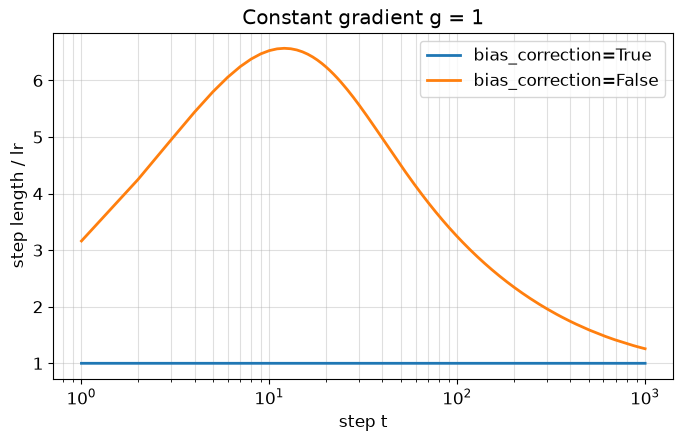

In [33]:
plt.figure(figsize=(8, 4.5))
for bc, lengths in bc_runs.items():
    plt.semilogx(range(1, len(lengths) + 1), lengths / lr, linewidth=2, label=f'bias_correction={bc}')
plt.xlabel('step t')
plt.ylabel('step length / lr')
plt.title('Constant gradient g = 1')
plt.legend()
plt.grid(True, which='both', alpha=0.4)
plt.show()

**Вопрос.** Выведите длину шага без bias correction при $g_t \equiv 1$ как функцию $t$ и сравните с выводом ячейки. Чем это опасно в начале обучения?

**Ответ.** При постоянном градиенте $g_t=1$ и начальных значениях $m_0=v_0=0$ накопленные моменты равны:

$
m_t=\beta_1m_{t-1}+(1-\beta_1)=1-\beta_1^t,
$

$
v_t=\beta_2v_{t-1}+(1-\beta_2)=1-\beta_2^t.
$

Поэтому без bias correction, при отключённом weight decay, длина шага:

$
|\Delta\theta_t|
=\mathrm{lr}\,\frac{1-\beta_1^t}
{\sqrt{1-\beta_2^t}+\epsilon}.
$

При $\beta_1=0.9$, $\beta_2=0.999$ формула согласуется с экспериментом: шаг составляет 3.16 lr на первой итерации, достигает максимума 6.57 lr на 12-й, затем уменьшается до 3.24 lr на 100-й и 1.26 lr на 1000-й. При дальнейшем увеличении $t$ он приближается к lr. С bias correction оба исправленных момента равны 1, поэтому шаг практически равен lr на всех итерациях.
В начале обучения это опасно слишком большими обновлениями весов. Фактический шаг может в несколько раз превышать заданный learning rate, вызывая скачки loss, колебания или расходимость обучения.

## 3.3 Cosine schedule (0.5 балла)

Множитель learning rate для `LambdaLR` (шаг $t$ считается с нуля, $T$ — число шагов, $r$ — доля от начального lr в конце):
$$
\lambda(t) = r + (1 - r)\, \frac{1 + \cos\big(\pi \min(1,\, t / T)\big)}{2}.
$$
На интервале от нулевого шага до $T$ это то же расписание, что `CosineAnnealingLR(T_max=T, eta_min=r·lr)`; после $T$ наша функция остаётся на минимуме, в отличие от продолжения cosine в PyTorch; проверка — совпадение learning rate по шагам с вашим `MyAdamW`.

**Оценивание:** код — 0.3; эксперимент — 0; объяснение — 0.2 балла.

In [57]:
def cosine_lr(step, total_steps, min_ratio=0.0):
    progress = min(1.0, step / total_steps)

    return (min_ratio + (1 - min_ratio) * (1 + math.cos(math.pi * progress)) / 2)

In [35]:
T, r, base_lr = 500, 0.1, 3e-3
lam = [cosine_lr(t, T, r) for t in range(T + 1)]
assert abs(lam[0] - 1) < 1e-12 and abs(lam[T] - r) < 1e-12 and abs(cosine_lr(2 * T, T, r) - r) < 1e-12
assert abs(lam[T // 2] - (r + (1 - r) / 2)) < 1e-9


def lr_trace(make_scheduler, steps=T):
    p = torch.zeros(1, requires_grad=True)
    optimizer = MyAdamW([p], lr=base_lr)
    scheduler = make_scheduler(optimizer)
    trace = []
    for _ in range(steps):
        trace.append(scheduler.get_last_lr()[0])
        optimizer.step()
        scheduler.step()
    return np.array(trace)


mine = lr_trace(lambda opt: torch.optim.lr_scheduler.LambdaLR(opt, lambda t: cosine_lr(t, T, r)))
ref = lr_trace(lambda opt: torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=T, eta_min=r * base_lr))
assert np.allclose(mine, ref, rtol=1e-6, atol=1e-12)

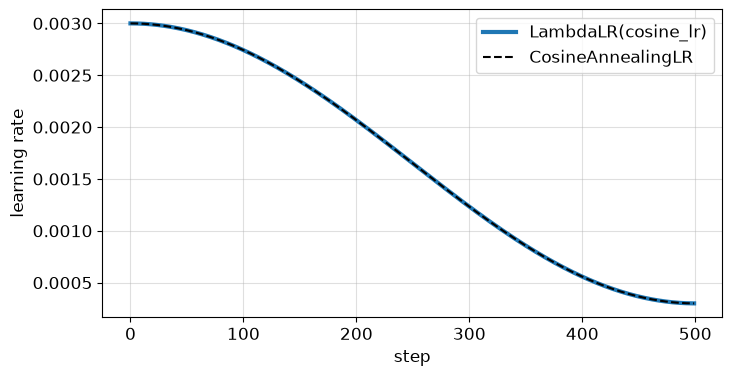

In [36]:
plt.figure(figsize=(8, 4))
plt.plot(mine, linewidth=3, label='LambdaLR(cosine_lr)')
plt.plot(ref, 'k--', linewidth=1.5, label='CosineAnnealingLR')
plt.xlabel('step')
plt.ylabel('learning rate')
plt.legend()
plt.grid(True, alpha=0.4)
plt.show()

**Вопрос.** Зачем уменьшать learning rate к концу обучения, если оптимизатор и так адаптивный? Что происходит со стохастическим методом при постоянном шаге около минимума?

**Ответ.** Адаптивный оптимизатор подбирает масштаб обновлений для отдельных параметров, но их общую величину всё равно задаёт learning rate. Его уменьшение к концу обучения позволяет делать более мелкие шаги и точнее приблизиться к минимуму. На графике lr плавно снижается с 0.003 до 0.0003, а собственное расписание совпадает с библиотечным.

При постоянном learning rate градиенты разных мини-батчей продолжают немного отличаться даже около минимума. Поэтому параметры обычно колеблются вокруг него, а loss выходит на шумное плато. Уменьшение lr ослабляет эти колебания и помогает стабилизировать обучение.

---
# 4. ResNet на CIFAR-10

CIFAR-10: 50 000 + 10 000 цветных картинок $32 \times 32$, 10 классов. Весь датасет хранится одним `uint8`-тензором на `device` (≈ 180 MB), нормализация делается на лету над батчем.

In [40]:
N_TRAIN = 10_000 if FAST_MODE else 50_000
N_TEST = 2_000 if FAST_MODE else 10_000

cifar_train = datasets.CIFAR10(DATA_ROOT, train=True, download=True)
cifar_test = datasets.CIFAR10(DATA_ROOT, train=False, download=True)
CIFAR_CLASSES = cifar_train.classes


def to_tensors(ds, n):
    X = torch.from_numpy(ds.data[:n]).permute(0, 3, 1, 2).contiguous()   # uint8 (N, 3, 32, 32)
    return X.to(device), torch.tensor(ds.targets[:n]).to(device)


X_train, Y_train = to_tensors(cifar_train, N_TRAIN)
X_test, Y_test = to_tensors(cifar_test, N_TEST)
CIFAR_MEAN = (X_train.float() / 255).mean(dim=(0, 2, 3))
CIFAR_STD = (X_train.float() / 255).std(dim=(0, 2, 3))
X_train.shape, X_test.shape, CIFAR_MEAN, CIFAR_STD

100%|██████████| 170M/170M [15:09<00:00, 187kB/s]
/usr/local/lib/python3.13/dist-packages/torchvision/datasets/cifar.py:83: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  entry = pickle.load(f, encoding="latin1")


(torch.Size([50000, 3, 32, 32]),
 torch.Size([10000, 3, 32, 32]),
 tensor([0.4914, 0.4822, 0.4465], device='cuda:0'),
 tensor([0.2470, 0.2435, 0.2616], device='cuda:0'))

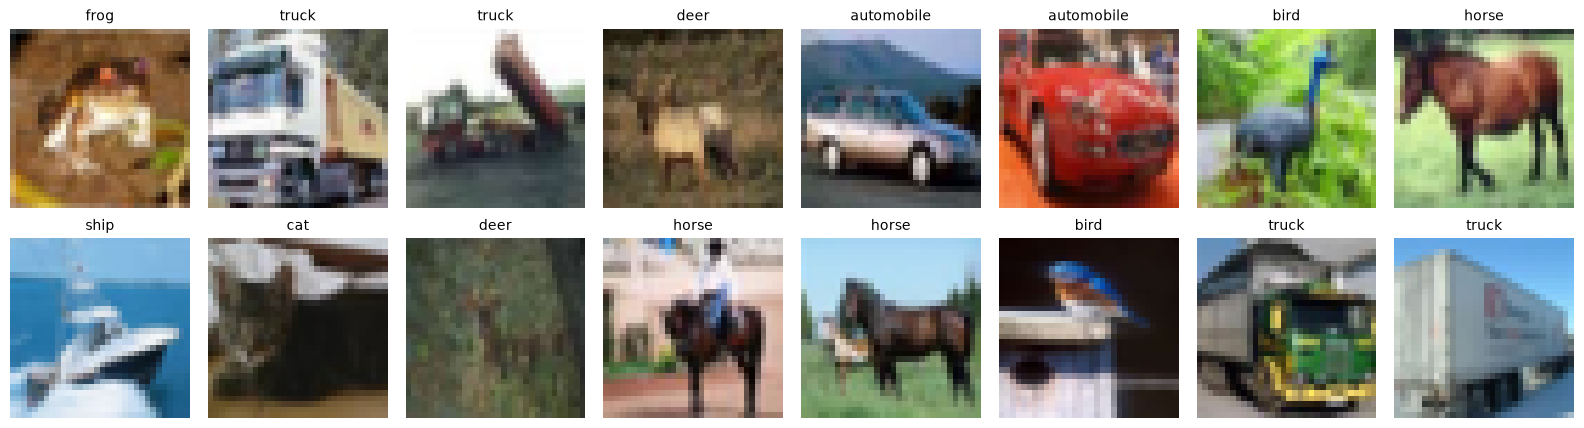

In [59]:
def normalize(x_uint8):
    return (x_uint8.float() / 255 - CIFAR_MEAN[:, None, None]) / CIFAR_STD[:, None, None]


fig, axes = plt.subplots(2, 8, figsize=(16, 4.5))
for ax, i in zip(axes.flat, range(16)):
    ax.imshow(X_train[i].permute(1, 2, 0).cpu())
    ax.set_title(CIFAR_CLASSES[Y_train[i]], fontsize=10)
    ax.axis('off')
plt.tight_layout()
plt.show()

## 4.1 ResNet для CIFAR (1 балл)

ResNet для CIFAR из §4.2 статьи [Deep Residual Learning for Image Recognition](https://arxiv.org/pdf/1512.03385), He et al., 2015: stem — свёртка $3 \times 3$ на 16 каналов с BN и ReLU; затем три стадии по $n$ блоков шириной 16, 32 и 64; в конце global average pooling и `Linear(64, 10)`. Глубина $6n + 2$. Первый блок второй и третьей стадии — со stride 2.

Блок (свёртки $3 \times 3$ без bias):
$$
F(x) = \mathrm{BN}\Big(\mathrm{Conv}\big(\mathrm{ReLU}(\mathrm{BN}(\mathrm{Conv}(x)))\big)\Big), \qquad y = \mathrm{ReLU}\big(F(x) + \mathrm{shortcut}(x)\big).
$$
Shortcut — `Identity`, а при смене формы (stride 2 или другое число каналов) — свёртка $1 \times 1$ с тем же stride и BN после неё. Флаги:

- `residual=False` — plain-сеть: сложения нет, shortcut-модулей нет;
- `separable=True` — каждая $3 \times 3$ свёртка блоков заменена на depthwise $3 \times 3$ и следующую за ней pointwise $1 \times 1$, обе без bias; stem остаётся обычным.

**Оценивание:** код — 1; эксперимент — 0; объяснение — 0 балла.

In [53]:
def conv3x3(c_in, c_out, stride=1, separable=False):
    if separable:
        return nn.Sequential(
            nn.Conv2d(c_in, c_in, 3, stride=stride, padding=1, groups=c_in, bias=False),
            nn.Conv2d(c_in, c_out, 1, bias=False),
        )

    return nn.Conv2d(c_in, c_out, 3, stride=stride, padding=1, bias=False)


class Block(nn.Module):
    def __init__(self, c_in, c_out, stride=1, residual=True, separable=False):
        super().__init__()
        self.residual = residual

        self.conv1 = conv3x3(c_in, c_out, stride=stride, separable=separable)
        self.bn1 = nn.BatchNorm2d(c_out)

        self.conv2 = conv3x3(c_out, c_out, separable=separable)
        self.bn2 = nn.BatchNorm2d(c_out)

        if residual:
            if stride == 1 and c_in == c_out:
                self.shortcut = nn.Identity()
            else:
                self.shortcut = nn.Sequential(
                    nn.Conv2d(c_in, c_out, 1,stride=stride, bias=False),
                    nn.BatchNorm2d(c_out),
                )

    def forward(self, x):
        out = F.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))

        if self.residual:
            out = out + self.shortcut(x)

        return F.relu(out)


class ResNetCIFAR(nn.Module):
    def __init__(self, depth=20, residual=True, separable=False, widths=(16, 32, 64), n_classes=10):
        super().__init__()
        assert (depth - 2) % 6 == 0
        n = (depth - 2) // 6

        self.stem = nn.Sequential(
            nn.Conv2d(3, widths[0], 3, padding=1, bias=False),
            nn.BatchNorm2d(widths[0]),
            nn.ReLU(),
        )

        blocks = []
        c_in = widths[0]

        for stage, c_out in enumerate(widths):
            for block_index in range(n):
                stride = (2 if stage > 0 and block_index == 0 else 1)

                blocks.append(
                    Block(c_in, c_out, stride=stride, residual=residual, separable=separable)
                )
                c_in = c_out

        self.blocks = nn.Sequential(*blocks)
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.fc = nn.Linear(widths[-1], n_classes)


    def forward(self, x):
        x = self.stem(x)
        x = self.blocks(x)
        x = self.pool(x).flatten(1)
        return self.fc(x)

In [40]:
x = torch.randn(2, 3, 32, 32)
for depth in [8, 20, 56]:
    for kwargs in [dict(), dict(residual=False), dict(separable=True)]:
        assert ResNetCIFAR(depth, **kwargs)(x).shape == (2, 10), (depth, kwargs)
assert n_params(ResNetCIFAR(20)) == 272_474
assert n_params(ResNetCIFAR(20, residual=False)) == 269_722
{name: n_params(ResNetCIFAR(depth, **kwargs)) for name, depth, kwargs in
 [('ResNet-20', 20, {}), ('ResNet-56', 56, {}), ('ResNet-20, separable', 20, dict(separable=True))]}

{'ResNet-20': 272474, 'ResNet-56': 855770, 'ResNet-20, separable': 40522}

## 4.2 Обучение (2 балла)

Реализуйте `train_cifar`: `MyAdamW` из 3.2 (weight decay только для параметров с `ndim > 1`), `LambdaLR` с `cosine_lr` из 3.3 до нуля за всё обучение ($r = 0$), cross-entropy, батч 256. После каждой эпохи — test accuracy. Вернуть историю `dict(train_loss, test_acc)` по эпохам.

Для ResNet-20 при `FAST_MODE = False` ориентир test accuracy — `TARGET_ACC` за `EPOCHS` эпох с `LR`. Это диагностический ориентир, не жёсткий порог балла: при заметном отставании проверьте normalisation, train/eval, scheduler и loss и опишите результат. Аугментации в этом протоколе нет. Каждый батч нормируйте через `normalize`; `scheduler.step()` вызывается после каждого `optimizer.step()`, `train_loss` — среднее по объектам за эпоху.

Test используется для учебных кривых с заранее фиксированными гиперпараметрами. Если выбираете гиперпараметры самостоятельно, выделите validation из train; test не используйте для выбора конфигурации.

**Оценивание:** код — 1.1; эксперимент — 0.6; объяснение — 0.3 балла.

In [47]:
EPOCHS = 3 if FAST_MODE else 20
LR = 0.003
TARGET_ACC = 0.82


def train_cifar(model, epochs, lr, weight_decay=0.05, batch_size=256, log=True):
    model = model.to(device)
    history = dict(train_loss=[], test_acc=[])
    start = time.time()

    optimizer = MyAdamW(
        [
            dict(
                params=[
                    p for p in model.parameters()
                    if p.ndim > 1
                ],
                weight_decay=weight_decay,
            ),
            dict(
                params=[
                    p for p in model.parameters()
                    if p.ndim <= 1
                ],
                weight_decay=0.0,
            ),
        ],
        lr=lr,
    )

    steps_per_epoch = math.ceil(len(X_train) / batch_size)
    total_steps = epochs * steps_per_epoch

    scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer,lr_lambda=lambda t: cosine_lr(t, total_steps),
)

    for epoch in range(epochs):
        model.train()
        loss_sum = 0.0
        count = 0

        for x, y in iterate_batches(X_train, Y_train, batch_size,transform=normalize):
            optimizer.zero_grad(set_to_none=True)

            loss = F.cross_entropy(model(x), y)
            loss.backward()

            optimizer.step()
            scheduler.step()

            loss_sum += loss.item() * len(y)
            count += len(y)

        epoch_loss = loss_sum / count
        test_accuracy = accuracy(predict_logits(model, X_test, transform=normalize), Y_test)

        history['train_loss'].append(epoch_loss)
        history['test_acc'].append(test_accuracy)

        if log:
            print(
                f'Epoch {epoch + 1:2d}/{epochs}: '
                f'loss={epoch_loss:.4f}, '
                f'test_acc={test_accuracy:.4f}, '
                f'time={(time.time() - start) / 60:.1f} min'
            )

    return history

In [60]:
set_seed(0)
resnet20 = ResNetCIFAR(20)
started = time.perf_counter()
history = train_cifar(resnet20, EPOCHS, LR)
RUN_TIMES['cifar_resnet20_seconds'] = time.perf_counter() - started
history_cifar = history
test_acc = history['test_acc'][-1]
train_acc = accuracy(predict_logits(resnet20, X_train[:10_000], transform=normalize), Y_train[:10_000])
if not FAST_MODE and test_acc < TARGET_ACC:
    print(f'Accuracy {test_acc:.3f} ниже ориентира {TARGET_ACC:.2f}: проверьте протокол и обсудите результат.')
{'train acc': train_acc, 'test acc': test_acc}

Epoch  1/20: loss=1.4326, test_acc=0.5789, time=0.3 min
Epoch  2/20: loss=0.9588, test_acc=0.6193, time=0.7 min
Epoch  3/20: loss=0.7666, test_acc=0.6266, time=1.0 min
Epoch  4/20: loss=0.6466, test_acc=0.7071, time=1.3 min
Epoch  5/20: loss=0.5601, test_acc=0.7726, time=1.6 min
Epoch  6/20: loss=0.4939, test_acc=0.7914, time=1.9 min
Epoch  7/20: loss=0.4299, test_acc=0.7221, time=2.2 min
Epoch  8/20: loss=0.3740, test_acc=0.7788, time=2.5 min
Epoch  9/20: loss=0.3193, test_acc=0.7848, time=2.8 min
Epoch 10/20: loss=0.2621, test_acc=0.8153, time=3.1 min
Epoch 11/20: loss=0.2114, test_acc=0.7997, time=3.4 min
Epoch 12/20: loss=0.1582, test_acc=0.7945, time=3.8 min
Epoch 13/20: loss=0.1069, test_acc=0.8148, time=4.1 min
Epoch 14/20: loss=0.0673, test_acc=0.8251, time=4.4 min
Epoch 15/20: loss=0.0394, test_acc=0.8255, time=4.7 min
Epoch 16/20: loss=0.0235, test_acc=0.8268, time=5.0 min
Epoch 17/20: loss=0.0158, test_acc=0.8268, time=5.3 min
Epoch 18/20: loss=0.0128, test_acc=0.8263, time=

{'train acc': 1.0, 'test acc': 0.8264999985694885}

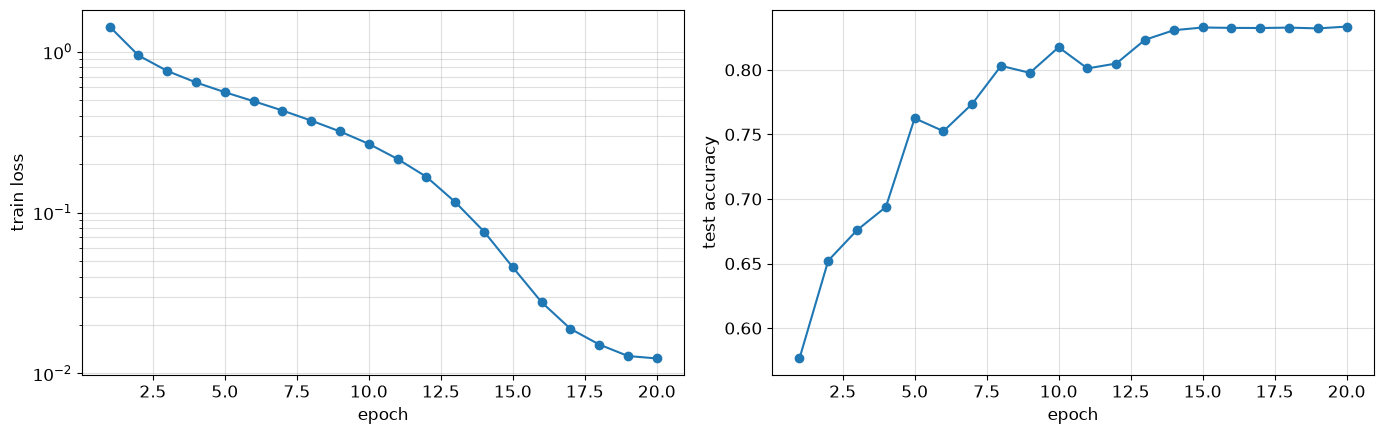

In [43]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))
epochs_axis = range(1, len(history['test_acc']) + 1)
ax1.semilogy(epochs_axis, history['train_loss'], 'o-')
ax1.set_ylabel('train loss')
ax2.plot(epochs_axis, history['test_acc'], 'o-')
ax2.set_ylabel('test accuracy')
for ax in (ax1, ax2):
    ax.set_xlabel('epoch')
    ax.grid(True, which='both', alpha=0.4)
plt.tight_layout()
plt.show()

**Вопрос.** Какой разрыв между train и test accuracy в конце обучения? Как ведут себя train loss и test accuracy на последних эпохах, когда learning rate уходит к нулю?

**Ответ.**
В конце обучения train accuracy на первых 10 000 обучающих объектах составила 99.98%, test accuracy — 83.35%. Разрыв равен 16.63, что указывает на заметный разрыв в обобщении.
На последних эпохах, когда learning rate приближается к нулю, train loss продолжает снижаться, но всё медленнее: с 0.0277 на 16-й эпохе до 0.0124 на 20-й. Test accuracy при этом выходит на плато около 83.2–83.35%. Таким образом, дальнейшее улучшение на обучающих данных почти не повышает качество на тестовых. Устойчивого падения test accuracy также не наблюдается.

## 4.3 Абляции (1.5 балла)

Сравните **plain-20 и plain-56** при одинаковых `ABL_EPOCHS` и `LR`. Это два дополнительных обучения. Результат — `ablation[name] = dict(params, train_acc, test_acc, minutes, history)`, где `train_acc` считается на первых 10 000 объектах train, а `history` возвращается `train_cifar`.

Перед каждой конфигурацией вызовите `set_seed(0)`. Проверяем гипотезу: увеличение глубины plain-сети может затруднить оптимизацию даже на train ([He et al., 2015](https://arxiv.org/pdf/1512.03385)). Это не обещание, что при данном optimizer и коротком бюджете эффект обязательно появится. Отличайте результат «хуже на train» от «лучше на train, хуже на test». Для сравнения с residual-сетями нужен одинаковый протокол; основной ResNet-20 обучался дольше, его финальную accuracy нельзя напрямую трактовать как контроль этого опыта.

**Оценивание:** код — 0.2; эксперимент — 0.7; объяснение — 0.6 балла.

In [49]:
ABL_EPOCHS = 2 if FAST_MODE else 10
ABLATIONS = {
    'plain-20': dict(depth=20, residual=False),
    'plain-56': dict(depth=56, residual=False),
}

In [65]:
ablation = {}
for name, config in ABLATIONS.items():
    set_seed(0)
    model = ResNetCIFAR(**config)

    started = time.perf_counter()
    hist = train_cifar(model, ABL_EPOCHS, LR)

    train_accuracy = accuracy(predict_logits(model, X_train[:10_000], transform=normalize),Y_train[:10_000])

    minutes = (time.perf_counter() - started) / 60

    ablation[name] = dict(
        params=n_params(model),
        train_acc=train_accuracy,
        test_acc=hist['test_acc'][-1],
        minutes=minutes,
        history=hist,
    )

print(f'{"model":<22}{"params":>9}{"train acc":>11}{"test acc":>10}{"minutes":>9}')
for name, res in ablation.items():
    print(f'{name:<22}{res["params"]:>9,}{res["train_acc"]:>11.4f}{res["test_acc"]:>10.4f}{res["minutes"]:>9.1f}')

Epoch  1/10: loss=1.7090, test_acc=0.3409, time=0.3 min
Epoch  2/10: loss=1.3344, test_acc=0.5415, time=0.6 min
Epoch  3/10: loss=1.0910, test_acc=0.5638, time=0.9 min
Epoch  4/10: loss=0.9304, test_acc=0.6724, time=1.2 min
Epoch  5/10: loss=0.7957, test_acc=0.6935, time=1.5 min
Epoch  6/10: loss=0.6884, test_acc=0.7202, time=1.8 min
Epoch  7/10: loss=0.5946, test_acc=0.7645, time=2.1 min
Epoch  8/10: loss=0.5175, test_acc=0.7822, time=2.4 min
Epoch  9/10: loss=0.4630, test_acc=0.7887, time=2.7 min
Epoch 10/10: loss=0.4350, test_acc=0.7896, time=3.0 min
Epoch  1/10: loss=2.0009, test_acc=0.2015, time=0.9 min
Epoch  2/10: loss=1.8719, test_acc=0.2646, time=1.8 min
Epoch  3/10: loss=1.8151, test_acc=0.3210, time=2.7 min
Epoch  4/10: loss=1.7128, test_acc=0.2905, time=3.6 min
Epoch  5/10: loss=1.5971, test_acc=0.3887, time=4.5 min
Epoch  6/10: loss=1.4987, test_acc=0.4212, time=5.4 min
Epoch  7/10: loss=1.3826, test_acc=0.4789, time=6.3 min
Epoch  8/10: loss=1.2780, test_acc=0.4894, time=

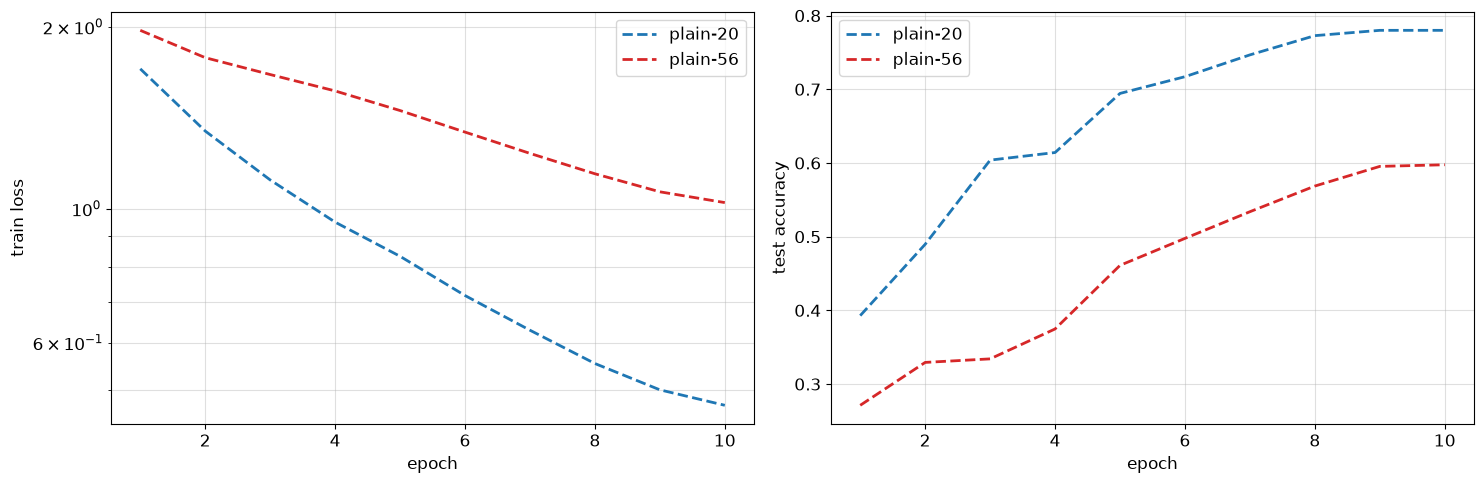

In [47]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))
for name in ABLATIONS:
    hist = ablation[name]['history']
    style = '-' if name.startswith('ResNet') else '--'
    color = 'tab:blue' if '20' in name else 'tab:red'
    epochs_axis = range(1, len(hist['train_loss']) + 1)
    ax1.semilogy(epochs_axis, hist['train_loss'], style, color=color, linewidth=2, label=name)
    ax2.plot(epochs_axis, hist['test_acc'], style, color=color, linewidth=2, label=name)
ax1.set_ylabel('train loss')
ax2.set_ylabel('test accuracy')
for ax in (ax1, ax2):
    ax.set_xlabel('epoch')
    ax.grid(True, which='both', alpha=0.4)
    ax.legend()
plt.tight_layout()
plt.show()

**Вопрос.** Есть ли в вашем прогоне ухудшение train loss при увеличении глубины? Как изменились train и test accuracy? Какие наблюдения говорят о трудностях оптимизации, а какие — о переобучении? Если ухудшения на train нет, напишите это. Предложите **один** следующий контрольный эксперимент, позволяющий проверить ваше объяснение; запускать его не требуется.

**Ответ.**
В моём прогоне увеличение глубины с 20 до 56 слоёв ухудшило результат на train: финальный train loss вырос с 0.4725 до 1.0231, а train accuracy снизилась с 84.65% до 63.75% - это на 20.90. Test accuracy также снизилась: с 78.00% до 59.76%, на 18.24

Несмотря на большее число параметров, более глубокая plain-сеть хуже обучается даже на тренировочных данных. При переобучении ожидалась бы другая картина: улучшение качества на train при ухудшении на test. Разрыв train–test составляет 6.65 у plain-20 и 3.99 у plain-56, поэтому отставание plain-56 нельзя объяснить только переобучением.

Контрольный эксперимент: обучить residual ResNet-56 при тех же seed, learning rate и 10 эпох. Если её train loss окажется ниже, чем у plain-56, это подтвердит объяснение, что shortcut-связи облегчают оптимизацию глубокой сети.

---
# 5. Атаки

Модель — маленькая CNN на FashionMNIST (пиксели в $[0, 1]$, без `Normalize`). В финальном режиме модель учится на полном train, а серии атак идут по фиксированным 1000 test-объектам. Раздел 5.1 обязателен; далее выполняется только ветка, выбранная в `ATTACK_TRACK`. Все модели во время оценки атак находятся в `eval()`. Метрики на такой подвыборке имеют sampling noise; близкие результаты не следует ранжировать как надёжное преимущество.

In [7]:
N_FM_TRAIN = 12_000 if FAST_MODE else 60_000
N_FM_TEST = 256 if FAST_MODE else 1_000
FM_EPOCHS = 2 if FAST_MODE else 5

fm_train = datasets.FashionMNIST(DATA_ROOT, train=True, download=True)
fm_test = datasets.FashionMNIST(DATA_ROOT, train=False, download=True)
FM_CLASSES = fm_train.classes


def fm_tensors(ds, n):
    return (ds.data[:n, None].float() / 255).to(device), ds.targets[:n].to(device)


XF_train, YF_train = fm_tensors(fm_train, N_FM_TRAIN)
XF_test, YF_test = fm_tensors(fm_test, N_FM_TEST)
XF_train.shape, XF_test.shape

100%|██████████| 26.4M/26.4M [00:01<00:00, 13.7MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 212kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.89MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 21.0MB/s]


(torch.Size([60000, 1, 28, 28]), torch.Size([1000, 1, 28, 28]))

Модель, обучение и атаки FGSM и PGD в $L_\infty$ — готовый код:

In [11]:
class SmallCNN(nn.Module):
    def __init__(self, n_classes=10):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
        )
        self.classifier = nn.Linear(64 * 7 * 7, n_classes)

    def forward(self, x):
        return self.classifier(self.features(x).flatten(1))


def train_fm(model, epochs=FM_EPOCHS, lr=1e-3):
    model = model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    for _ in range(epochs):
        model.train()
        for x, y in iterate_batches(XF_train, YF_train, 128):
            loss = F.cross_entropy(model(x), y)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
    model.eval()
    return model

In [12]:
def fgsm_attack(model, x, y, eps):
    x = x.detach()
    x_adv = x.clone().requires_grad_(True)
    with torch.enable_grad():
        grad, = torch.autograd.grad(F.cross_entropy(model(x_adv), y), x_adv)
    return (x + eps * grad.sign()).clamp(0, 1).detach()


def pgd_attack(model, x, y, eps, alpha, steps, random_start=True):
    x = x.detach()
    x_adv = (x + torch.empty_like(x).uniform_(-eps, eps)).clamp(0, 1) if random_start else x.clone()
    for _ in range(steps):
        x_adv.requires_grad_(True)
        with torch.enable_grad():
            grad, = torch.autograd.grad(F.cross_entropy(model(x_adv), y), x_adv)
        x_adv = x_adv.detach() + alpha * grad.sign()
        x_adv = torch.clamp(x_adv, min=x - eps, max=x + eps).clamp(0, 1)
    return x_adv.detach()


def pgd(model, x, y, eps, steps=20):
    return pgd_attack(model, x, y, eps, alpha=2.5 * eps / steps, steps=steps)


def attack_accuracy(model, X, Y, attack=None, batch_size=500, **attack_kwargs):
    model.eval()
    correct = 0
    for i in range(0, len(X), batch_size):
        x, y = X[i:i + batch_size], Y[i:i + batch_size]
        if attack is not None:
            x = attack(model, x, y, **attack_kwargs)
        with torch.no_grad():
            correct += (model(x).argmax(dim=1) == y).sum().item()
    return correct / len(X)


def assert_no_param_grads(model):
    assert all(p.grad is None for p in model.parameters())

In [15]:
set_seed(0)
started = time.perf_counter()
model_a = train_fm(SmallCNN())
RUN_TIMES['fashion_standard_seconds'] = time.perf_counter() - started
model_a.zero_grad(set_to_none=True)
{'clean': attack_accuracy(model_a, XF_test, YF_test),
 'FGSM, eps=0.1': attack_accuracy(model_a, XF_test, YF_test, fgsm_attack, eps=0.1),
 'PGD-20, eps=0.1': attack_accuracy(model_a, XF_test, YF_test, pgd, eps=0.1)}

{'clean': 0.918, 'FGSM, eps=0.1': 0.071, 'PGD-20, eps=0.1': 0.007}

## 5.1 PGD в $L_2$ (1 балл)

Ограничение $\|\delta\|_2 \le \varepsilon$. Линеаризация loss (как при выводе FGSM) даёт шаг по нормированному градиенту, а проекция на шар — масштабирование:
$$
x' = x^{(k)} + \alpha\, \frac{g}{\|g\|_2}, \qquad
\delta = x' - x, \qquad
x^{(k+1)} = \mathrm{clip}_{[0, 1]}\Big(x + \delta \cdot \min\big(1,\, \tfrac{\varepsilon}{\|\delta\|_2}\big)\Big).
$$
Нормы — по каждой картинке отдельно. Старт из $x$ (без random start).

**Оценивание:** код — 0.6; эксперимент — 0.2; объяснение — 0.2 балла.

In [72]:
def pgd_l2(model, x, y, eps, alpha, steps):
    x = x.detach()
    x_adv = x.clone()

    for _ in range(steps):
        x_adv = x_adv.detach().requires_grad_(True)

        with torch.enable_grad():
            loss = F.cross_entropy(model(x_adv), y)
            grad, = torch.autograd.grad(loss, x_adv)

        grad_norm = (grad.flatten(1).norm(dim=1).view(-1, 1, 1, 1).clamp_min(1e-12))

        candidate = (x_adv.detach() + alpha * grad / grad_norm)

        delta = candidate - x
        delta_norm = (
            delta.flatten(1).norm(dim=1)
            .view(-1, 1, 1, 1)
            .clamp_min(1e-12)
        )

        scale = (eps / delta_norm).clamp(max=1.0)
        x_adv = (x + delta * scale).clamp(0, 1).detach()

    return x_adv.detach()

In [53]:
x, y = XF_test[:500], YF_test[:500]
eps2 = 2.0
x_adv = pgd_l2(model_a, x, y, eps=eps2, alpha=2.5 * eps2 / 20, steps=20)
assert (x_adv - x).flatten(1).norm(dim=1).max() <= eps2 + 1e-4
assert x_adv.min() >= 0 and x_adv.max() <= 1 and not x_adv.requires_grad
assert_no_param_grads(model_a)
acc_clean, acc_l2 = attack_accuracy(model_a, x, y), attack_accuracy(model_a, x_adv, y)
print(f'Падение accuracy под PGD-L2: {acc_clean - acc_l2:.3f}; маленькое падение требует диагностики.')
acc_clean, acc_l2

Падение accuracy под PGD-L2: 0.920; маленькое падение требует диагностики.


(0.92, 0.0)

In [73]:
def pgd_l2_20(model, x, y, eps):
    return pgd_l2(model, x, y, eps, alpha=2.5 * eps / 20, steps=20)


eps_l2 = [0.0, 0.5, 1.0, 1.5, 2.0, 3.0, 4.0]
acc_l2 = [attack_accuracy(model_a, XF_test, YF_test, pgd_l2_20, eps=e) for e in eps_l2]
acc_linf = attack_accuracy(model_a, XF_test, YF_test, pgd, eps=0.1)
dict(zip(eps_l2, acc_l2)), acc_linf

({0.0: 0.918, 0.5: 0.443, 1.0: 0.08, 1.5: 0.01, 2.0: 0.0, 3.0: 0.0, 4.0: 0.0},
 0.008)

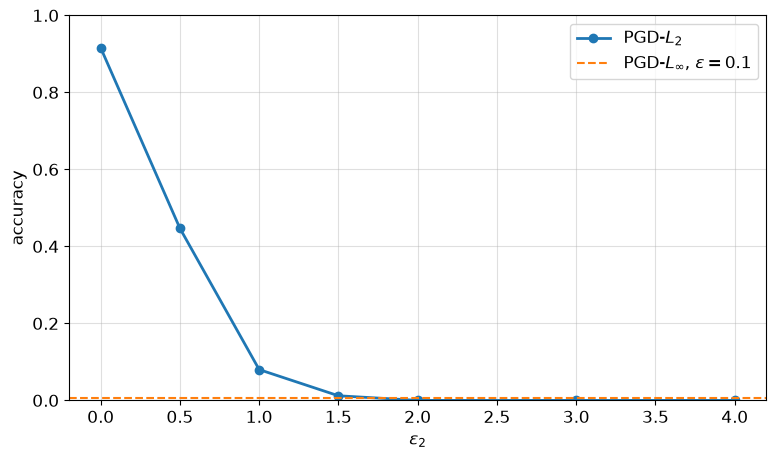

In [55]:
plt.figure(figsize=(9, 5))
plt.plot(eps_l2, acc_l2, 'o-', linewidth=2, label=r'PGD-$L_2$')
plt.axhline(acc_linf, color='tab:orange', linestyle='--', label=r'PGD-$L_\infty$, $\varepsilon = 0.1$')
plt.xlabel(r'$\varepsilon_2$')
plt.ylabel('accuracy')
plt.ylim(0, 1)
plt.legend()
plt.grid(True, alpha=0.4)
plt.show()

Возмущения обеих атак на одних картинках; $\varepsilon_2$ — ближайшая по accuracy точка проверенной сетки. Если разница велика, сравнение не следует называть сравнением при равной силе атаки. Цветовая шкала каждой карты нормирована отдельно; абсолютные нормы выведены под рисунком:

Ближайшая точка сетки: eps2=1.5, accuracy gap=0.005


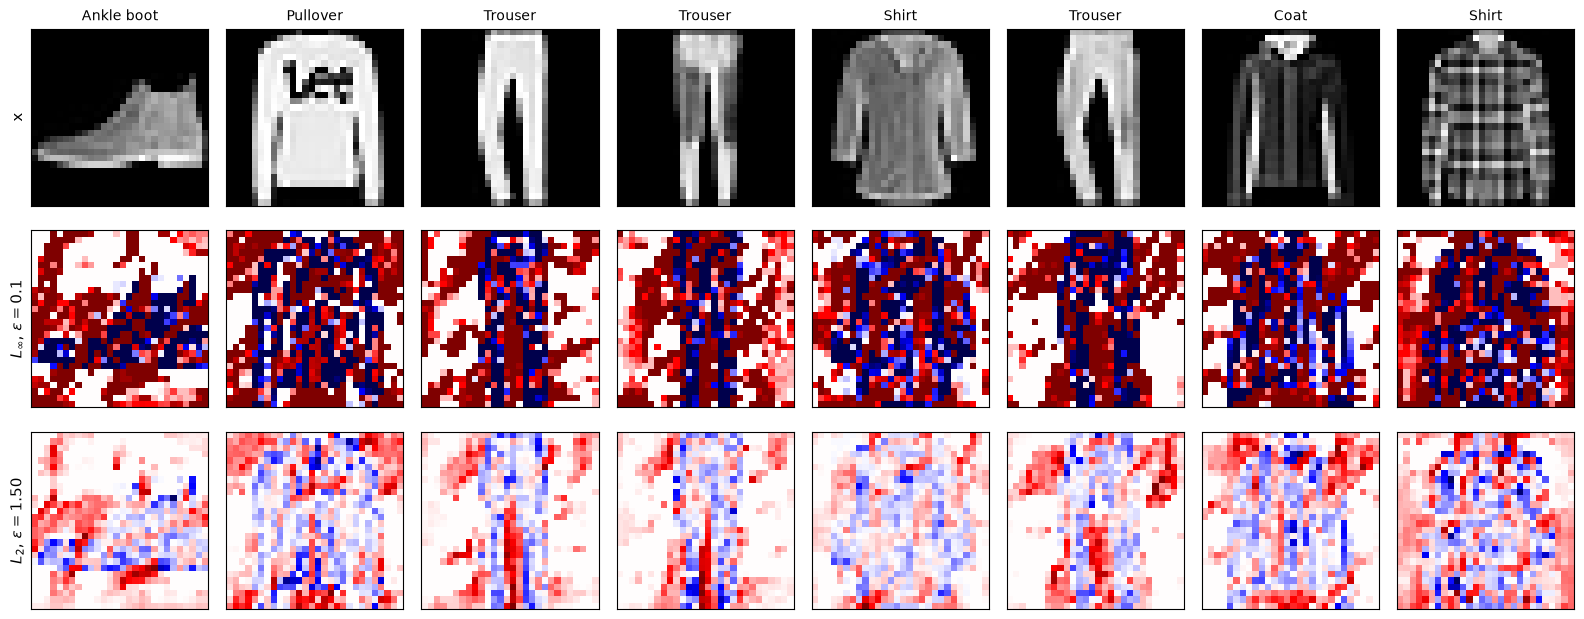

$L_\infty$, $\varepsilon=0.1$ L_inf = 0.100   L_2 = 2.098
$L_2$, $\varepsilon=1.50$    L_inf = 0.253   L_2 = 1.492


In [56]:
# Поиск ближайшей проверенной точки не предполагает монотонность конечной PGD.
match_idx = int(np.argmin(np.abs(np.asarray(acc_l2) - acc_linf)))
eps2_match = float(eps_l2[match_idx])
print(f'Ближайшая точка сетки: eps2={eps2_match}, accuracy gap={abs(acc_l2[match_idx] - acc_linf):.3f}')
x8, y8 = XF_test[:8], YF_test[:8]
torch.manual_seed(0)
deltas = {r'$L_\infty$, $\varepsilon=0.1$': pgd(model_a, x8, y8, 0.1) - x8,
          rf'$L_2$, $\varepsilon={eps2_match:.2f}$': pgd_l2_20(model_a, x8, y8, eps2_match) - x8}
fig, axes = plt.subplots(3, 8, figsize=(16, 6.5))
for i in range(8):
    axes[0, i].imshow(x8[i, 0].cpu(), cmap='gray', vmin=0, vmax=1)
    axes[0, i].set_title(FM_CLASSES[y8[i]], fontsize=10)
    for row, d in enumerate(deltas.values(), start=1):
        vmax = d[i].abs().max().item()
        axes[row, i].imshow(d[i, 0].cpu(), cmap='seismic', vmin=-vmax, vmax=vmax)
for ax in axes.flat:
    ax.set_xticks([])
    ax.set_yticks([])
for ax, label in zip(axes[:, 0], ['x'] + list(deltas)):
    ax.set_ylabel(label, fontsize=11)
plt.tight_layout()
plt.show()
for name, d in deltas.items():
    print(f'{name:<28} L_inf = {d.abs().amax(dim=(1, 2, 3)).mean():.3f}   L_2 = {d.flatten(1).norm(dim=1).mean():.3f}')

**Вопрос.** Какая точка сетки $\varepsilon_2$ ближе всего по accuracy к $L_\infty$-атаке с $\varepsilon = 0.1$ и как велик остаточный разрыв? Какова $L_2$-норма самого $L_\infty$-возмущения? Где сосредоточено $L_2$-возмущение на ваших изображениях и как это связано с нормированным градиентом?

**Ответ.**
Ближайшая точка сетки $\varepsilon_2=1.5$: accuracy после $L_2$-атаки равна 0.012, а после $L_\infty$-атаки с $\varepsilon=0.1$ - 0.007. Остаточный разрыв составляет 0.005, или 0.5 процента, поэтому на этой выборке атаки дают близкую accuracy.

Средняя $L_2$-норма самого $L_\infty$-возмущения на восьми показанных изображениях равна 2.098. У $L_2$-возмущения она составляет 1.492, при этом максимальное изменение отдельного пикселя в среднем достигает 0.253, превышая ограничение 0.1 для $L_\infty$-атаки.

На изображениях $L_2$-возмущение распределено неравномерно: заметные изменения видны около контуров и деталей объектов, а также на отдельных участках фона. Это связано с шагом по нормированному градиенту $g/\|g\|_2$: нормировка сохраняет соотношение компонент, поэтому пиксели с большим модулем градиента изменяются сильнее. В отличие от этого, $L_\infty$-атака использует знак градиента, из-за чего её возмущение выглядит более равномерным по величине.

## 5.2 Targeted attack (2 балла, вариант на выбор)

Выполняется при `ATTACK_TRACK = 'targeted'`. Ветку 5.3 при этом можно оставить пустой.

Цель — не просто ошибка, а заданный класс $t$: минимизируем loss по целевой метке
$$
x^{(k+1)} = \Pi_{B_\infty(x, \varepsilon)}\Big[x^{(k)} - \alpha\, \mathrm{sign}\, \nabla_x L\big(f(x^{(k)}), t\big)\Big].
$$

1. Реализуйте `pgd_targeted` ($L_\infty$, random start, как `pgd_attack`).
2. Реализуйте `targeted_success_matrix`: $S[s, t]$ — доля всех картинок класса $s$, которые после атаки с целью $t$ классифицируются как $t$, включая изначально ошибочные. Верните CPU-тензор; диагональ и строки отсутствующих классов — `nan`. Обрабатывайте вход батчами не более 128 объектов, сигнатуру менять не нужно. Сопоставьте результат с готовой clean confusion matrix ниже.

**Оценивание:** код — 1; эксперимент — 0.4; объяснение — 0.6 балла.

In [8]:
if ATTACK_TRACK == 'targeted':
    def pgd_targeted(model, x, target, eps, alpha, steps):
        x = x.detach()
        x_adv = (x + torch.empty_like(x).uniform_(-eps, eps)).clamp(0, 1)

        for _ in range(steps):
            x_adv = x_adv.detach().requires_grad_(True)

            with torch.enable_grad():
                loss = F.cross_entropy(model(x_adv), target)
                grad, = torch.autograd.grad(loss, x_adv)

            x_adv = (x_adv.detach() - alpha * grad.sign())
            x_adv = torch.clamp(x_adv, min=x - eps, max=x + eps).clamp(0, 1)

        return x_adv.detach()


    def targeted_success_matrix(model, x, y, eps, steps=20, n_classes=10):
        model.eval()

        S = torch.full((n_classes, n_classes),float('nan'),device='cpu')

        for source in range(n_classes):
            indices = (y == source).nonzero(as_tuple=True)[0]

            if indices.numel() == 0:
                continue

            for target_class in range(n_classes):
                if target_class == source:
                    continue

                hits = 0

                for start in range(0, len(indices), 128):
                    batch_indices = indices[start:start + 128]
                    xb = x[batch_indices]

                    targets = torch.full(
                        (len(xb),),
                        target_class,
                        dtype=torch.long,
                        device=xb.device,
                    )

                    adv = pgd_targeted(
                        model,
                        xb,
                        targets,
                        eps=eps,
                        alpha=2.5 * eps / steps,
                        steps=steps,
                    )

                    with torch.no_grad():
                        hits += (model(adv).argmax(dim=1)== targets).sum().item()

                S[source, target_class] = (hits / len(indices))

        return S

In [16]:
if ATTACK_TRACK == 'targeted':
    torch.manual_seed(0)
    x, y = XF_test[:1000], YF_test[:1000]
    target = (y + 1) % 10
    x_t = pgd_targeted(model_a, x, target, eps=0.1, alpha=0.0125, steps=20)
    assert (x_t - x).abs().max() <= 0.1 + 1e-6 and x_t.min() >= 0 and x_t.max() <= 1
    assert_no_param_grads(model_a)
    with torch.no_grad():
        hit_rate = (model_a(x_t).argmax(dim=1) == target).float().mean().item()
    print(f'Targeted hit rate: {hit_rate:.3f}; сравните с частотой целевого класса до атаки.')
    hit_rate

Targeted hit rate: 0.770; сравните с частотой целевого класса до атаки.


Clean confusion matrix (строки: true, столбцы: predicted):
[[0.93 0.   0.01 0.03 0.   0.   0.04 0.   0.   0.  ]
 [0.   0.99 0.   0.01 0.   0.   0.   0.   0.   0.  ]
 [0.04 0.   0.86 0.01 0.05 0.   0.05 0.   0.   0.  ]
 [0.05 0.   0.01 0.88 0.03 0.   0.02 0.   0.   0.  ]
 [0.   0.   0.05 0.03 0.9  0.   0.03 0.   0.   0.  ]
 [0.   0.   0.   0.   0.   0.98 0.   0.01 0.   0.01]
 [0.09 0.   0.06 0.03 0.07 0.   0.74 0.   0.   0.  ]
 [0.   0.   0.   0.   0.   0.   0.   0.99 0.01 0.  ]
 [0.   0.   0.   0.   0.   0.   0.01 0.   0.99 0.  ]
 [0.   0.   0.   0.   0.   0.01 0.   0.04 0.   0.95]]


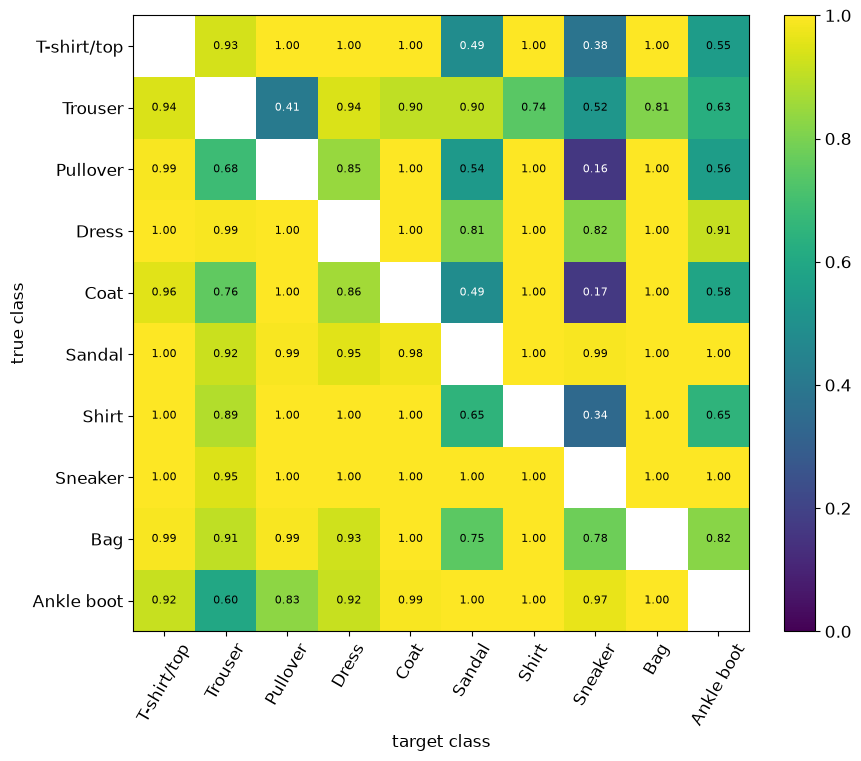

In [17]:
if ATTACK_TRACK == 'targeted':
    torch.manual_seed(0)
    S = targeted_success_matrix(model_a, XF_test, YF_test, eps=0.1)
    assert S.shape == (10, 10) and torch.isnan(S.diagonal()).all()
    pred_clean = predict_logits(model_a, XF_test).argmax(1)
    clean_confusion = torch.bincount((10 * YF_test + pred_clean).cpu(), minlength=100).reshape(10, 10).float()
    clean_confusion /= clean_confusion.sum(1, keepdim=True).clamp_min(1)
    print('Clean confusion matrix (строки: true, столбцы: predicted):')
    print(np.round(clean_confusion.numpy(), 2))

    fig, ax = plt.subplots(figsize=(9, 8))
    im = ax.imshow(S, cmap='viridis', vmin=0, vmax=1)
    for s, t in itertools.product(range(10), range(10)):
        if s != t:
            ax.text(t, s, f'{S[s, t]:.2f}', ha='center', va='center', fontsize=8,
                    color='white' if S[s, t] < 0.5 else 'black')
    ax.set_xticks(range(10), FM_CLASSES, rotation=60)
    ax.set_yticks(range(10), FM_CLASSES)
    ax.set_xlabel('target class')
    ax.set_ylabel('true class')
    plt.colorbar(im, fraction=0.046)
    plt.show()

**Вопрос.** Какие пары (истинный класс, целевой класс) атакуются легче всего, какие труднее? Симметрична ли матрица? Как это связано с тем, какие классы модель путает без атаки?

**Ответ.**
Легче всего атакуются пары, для которых targeted success составляет 1.00 по округлённым значениям, например T-shirt/top → Pullover, Pullover → Coat, Shirt → T-shirt/top и Sneaker → Ankle boot. Наиболее трудные переходы Pullover → Sneaker (0.16), Coat → Sneaker (0.17) и Shirt → Sneaker (0.34).

Матрица несимметрична: например, Pullover → Sneaker удаётся с частотой 0.16, а обратный переход Sneaker → Pullover - 1.00. Это означает, что достижимость целевого класса зависит от направления атаки.

Без атаки модель чаще путает похожие предметы одежды: например, Shirt → T-shirt/top (0.09) и Shirt → Coat (0.07). Оба перехода под targeted-атакой достигают 1.00, что согласуется с исходной путаницей. Однако высокая успешность возможна и между классами, которые модель почти не путает на чистых изображениях, например Sneaker → Pullover.



## 5.3 Transfer (2 балла, вариант на выбор)

Выполняется при `ATTACK_TRACK = 'transfer'`. Ветку 5.2 при этом можно оставить пустой.

Black-box сценарий: атакующий не видит модель-жертву, строит атаку на своей модели и надеется, что она перенесётся. Обучите `model_b` (та же архитектура, `set_seed(1)`) и MLP с двумя скрытыми слоями по 512 нейронов и ReLU (`set_seed(2)`). Атаки FGSM и PGD-20 с $\varepsilon = 0.1$, построенные на `model_a`, проверьте на всех трёх моделях. Результат — `transfer[attack][victim] = accuracy`, атаки `'clean'`, `'FGSM'`, `'PGD-20'`, жертвы `'model A (source)'`, `'model B'`, `'MLP'`.

**Оценивание:** код — 0.6; эксперимент — 0.8; объяснение — 0.6 балла.

In [ ]:
if ATTACK_TRACK == 'transfer':
    # ваш код
    raise NotImplementedError
    print(f'{"":<8}' + ''.join(f'{name:>18}' for name in transfer['clean']))
    for attack, row in transfer.items():
        print(f'{attack:<8}' + ''.join(f'{acc:>18.3f}' for acc in row.values()))

**Вопрос.** Для каждой жертвы укажите падение accuracy относительно её собственного clean baseline. Сравните с падением на source-модели. Какая атака и на какую архитектуру переносится лучше в вашем прогоне? Предложите объяснение и укажите, почему одного seed недостаточно для общего вывода о превосходстве архитектуры или атаки.

**Ответ.**

---
# 6. Adversarial training

## 6.1 PGD adversarial training (2 балла)

[Towards Deep Learning Models Resistant to Adversarial Attacks](https://arxiv.org/pdf/1706.06083), Madry et al., 2017:
$$
\min_\theta\; \mathbb E_{(x, y)} \Big[\max_{\|\delta\|_\infty \le \varepsilon} L\big(f_\theta(x + \delta), y\big)\Big].
$$
На каждом батче внутренний max приближается атакой, и шаг оптимизатора делается только по adversarial-примерам, без clean-части. Модель — с нуля.

Реализуйте `adversarial_train(model, eps, attack, epochs)`: `attack(model, x, y, eps)` возвращает detached `x_adv`. Используйте `torch.optim.Adam` с переданным `lr`, batch size 128, cross-entropy только на adversarial-примерах. Генерация атаки — в `eval()`, обновление весов — в `train()`; не дифференцируйте через построение атаки. После каждой эпохи записывайте clean, FGSM и PGD-20 accuracy на `XF_test[:1000]` с тем же $\varepsilon$. Перед возвратом включите `eval()` и очистите `.grad` параметров.

В обязательной части обучается одна модель с PGD-7. FGSM и FGSM-RS из готового словаря нужны только для бонуса 7.5.

**Оценивание:** код — 1; эксперимент — 0.6; объяснение — 0.4 балла.

In [18]:
def fgsm_rs_attack(model, x, y, eps):
    return pgd_attack(model, x, y, eps, alpha=1.25 * eps, steps=1, random_start=True)


def pgd7_attack(model, x, y, eps):
    return pgd_attack(model, x, y, eps, alpha=2.5 * eps / 7, steps=7)


TRAIN_ATTACKS = {'FGSM': fgsm_attack, 'FGSM-RS': fgsm_rs_attack, 'PGD-7': pgd7_attack}
AT_EPOCHS = 2 if FAST_MODE else 5

In [19]:
def adversarial_train(model, eps, attack, epochs=AT_EPOCHS, lr=1e-3, log=True):
    model = model.to(device)
    history = dict(clean=[], fgsm=[], pgd=[])

    optimizer = torch.optim.Adam(model.parameters(), lr=lr)

    x_eval = XF_test[:1000]
    y_eval = YF_test[:1000]

    for epoch in range(epochs):
        loss_sum = 0.0
        count = 0

        for x, y in iterate_batches(XF_train, YF_train, batch_size=128):
            optimizer.zero_grad(set_to_none=True)

            model.eval()
            x_adv = attack(model, x, y, eps).detach()

            model.train()
            loss = F.cross_entropy(model(x_adv), y)

            loss.backward()
            optimizer.step()

            loss_sum += loss.item() * len(y)
            count += len(y)

        model.eval()
        optimizer.zero_grad(set_to_none=True)

        clean_acc = attack_accuracy(model, x_eval, y_eval, batch_size=128)
        fgsm_acc = attack_accuracy(
            model, x_eval, y_eval,
            attack=fgsm_attack,
            batch_size=128,
            eps=eps,
        )
        pgd_acc = attack_accuracy(
            model, x_eval, y_eval,
            attack=pgd,
            batch_size=128,
            eps=eps,
        )

        history['clean'].append(clean_acc)
        history['fgsm'].append(fgsm_acc)
        history['pgd'].append(pgd_acc)

        if log:
            print(
                f'Epoch {epoch + 1}/{epochs}: '
                f'adv_loss={loss_sum / count:.4f}, '
                f'clean={clean_acc:.4f}, '
                f'FGSM={fgsm_acc:.4f}, '
                f'PGD20={pgd_acc:.4f}'
            )

    model.eval()
    optimizer.zero_grad(set_to_none=True)

    return history

In [20]:
EPS_TRAIN = 0.1
robust, at_history = {}, {}
for name in ['PGD-7']:
    print(name)
    set_seed(0)
    robust[name] = SmallCNN()
    started = time.perf_counter()
    at_history[name] = adversarial_train(robust[name], EPS_TRAIN, TRAIN_ATTACKS[name])
    RUN_TIMES['fashion_pgd_at_seconds'] = time.perf_counter() - started
if not FAST_MODE and at_history['PGD-7']['pgd'][-1] <= 0.5:
    print('PGD accuracy ниже ориентира 0.5: проверьте обучение и обсудите результат; это не автопровал задания.')

PGD-7
Epoch 1/5: adv_loss=1.0186, clean=0.8080, FGSM=0.6980, PGD20=0.6640
Epoch 2/5: adv_loss=0.8205, clean=0.8000, FGSM=0.6990, PGD20=0.6690
Epoch 3/5: adv_loss=0.7725, clean=0.8200, FGSM=0.7140, PGD20=0.6830
Epoch 4/5: adv_loss=0.7424, clean=0.8370, FGSM=0.7380, PGD20=0.7010
Epoch 5/5: adv_loss=0.7193, clean=0.8300, FGSM=0.7340, PGD20=0.6990


In [21]:
eps_grid = [0.0, 0.05, 0.1, 0.15, 0.2, 0.3]
models_eval = {'standard': model_a, 'PGD-AT': robust['PGD-7']}
torch.manual_seed(0)
robust_curves = {name: [attack_accuracy(m, XF_test, YF_test, pgd, eps=e) if e > 0 else attack_accuracy(m, XF_test, YF_test)
                        for e in eps_grid] for name, m in models_eval.items()}
for name, accs in robust_curves.items():
    print(f'{name:<10}' + ''.join(f'{a:>8.3f}' for a in accs))

standard     0.918   0.121   0.005   0.000   0.000   0.000
PGD-AT       0.830   0.774   0.702   0.514   0.138   0.001


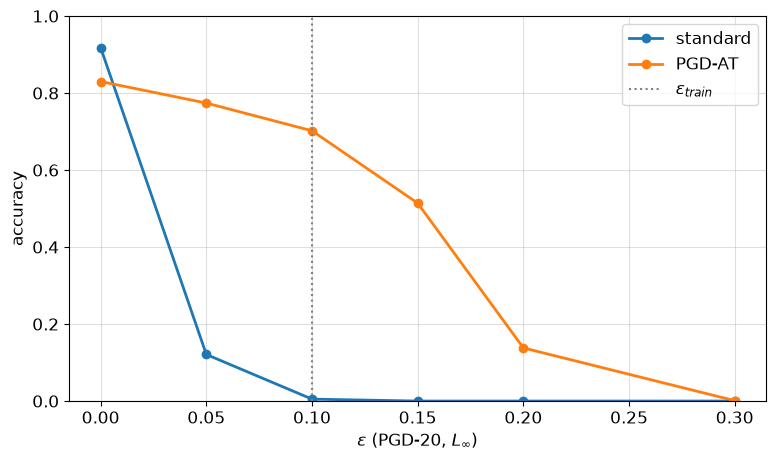

In [22]:
plt.figure(figsize=(9, 5))
for name, accs in robust_curves.items():
    plt.plot(eps_grid, accs, 'o-', linewidth=2, label=name)
plt.axvline(EPS_TRAIN, color='gray', linestyle=':', label=r'$\varepsilon_{train}$')
plt.xlabel(r'$\varepsilon$ (PGD-20, $L_\infty$)')
plt.ylabel('accuracy')
plt.ylim(0, 1)
plt.legend()
plt.grid(True, alpha=0.4)
plt.show()

**Вопрос.** Сколько стоит робастность в clean accuracy? Что происходит при $\varepsilon > \varepsilon_{\text{train}}$? Во сколько раз PGD-AT дороже обычного обучения по числу forward/backward?

**Ответ.**
Робастность стоила 8.8 процента clean accuracy: у стандартной модели она равна 91.8%, у PGD-AT - 83.0%. При этом под PGD-20 с обучающим радиусом $\varepsilon=0.1$ accuracy выросла с 0.5% до 70.2%.

При $\varepsilon>\varepsilon_{\text{train}}=0.1$ устойчивость постепенно теряется: accuracy PGD-AT снижается до 51.4% при 0.15, 13.8% при 0.2 и 0.1% при 0.3. Таким образом, защита частично сохраняется за пределами обучающего радиуса, но не распространяется на произвольно большие возмущения.

Для каждого батча PGD-7 требует семь forward/backward для построения атаки и ещё один forward/backward для обновления весов. Поэтому PGD-AT требует примерно в 8 раз больше пар проходов, чем обычное обучение.



## 6.2 Диагностика оценки robustness (1 балл)

Реализуйте `sanity_checks(model, x, y, eps)` и верните четыре accuracy:

- `fgsm` — после FGSM;
- `pgd20` — после PGD-20 с random start;
- `pgd100_x5` — PGD-100 с пятью random restarts: объект считается сломанным, если он ошибочно классифицирован хотя бы в одном restart **или уже на clean**;
- `eps_1` — после PGD-20 с $\varepsilon=1$.

Для каждого поля clean-ошибки тоже считаются ошибками: атака не должна «исправлять» robust accuracy. Атакуйте батчами не более 128. В `FAST_MODE` сокращается только число объектов, число шагов и restarts остаётся тем же.

Обычно усиление атаки уменьшает accuracy; обратный результат — повод проверить step size, random start и loss. Независимые конечные PGD-прогоны не дают гарантированного порядка результатов. Низкая accuracy при большом радиусе — полезная диагностика, но прохождение всех sanity checks не доказывает отсутствие gradient masking и не сертифицирует robustness. См. [Athalye et al., 2018](https://arxiv.org/abs/1802.00420).

Эксперимент проводится на фиксированных первых 128 объектах в FAST_MODE и 256 в финальном режиме. Это диагностика, а не точная оценка accuracy всего датасета.

**Оценивание:** код — 0.5; эксперимент — 0.2; объяснение — 0.3 балла.

In [23]:
def sanity_checks(model, x, y, eps):
    model.eval()

    totals = dict(fgsm=0, pgd20=0, pgd100_x5=0, eps_1=0)

    def correct_mask(images, labels):
        with torch.no_grad():
            return model(images).argmax(dim=1).eq(labels)

    for start in range(0, len(x), 128):
        xb = x[start:start + 128]
        yb = y[start:start + 128]

        clean_correct = correct_mask(xb, yb)

        adv = fgsm_attack(model, xb, yb, eps)
        totals['fgsm'] += (clean_correct & correct_mask(adv, yb)).sum().item()

        adv = pgd(model, xb, yb, eps, steps=20)
        totals['pgd20'] += (clean_correct & correct_mask(adv, yb)).sum().item()

        survives_all = clean_correct.clone()

        for _ in range(5):
            adv = pgd(model, xb, yb, eps, steps=100)
            survives_all &= correct_mask(adv, yb)

        totals['pgd100_x5'] += (survives_all.sum().item())

        adv = pgd(model, xb, yb, eps=1.0, steps=20)
        totals['eps_1'] += (clean_correct & correct_mask(adv, yb)).sum().item()

    return {name: value / len(x) for name, value in totals.items()}

In [24]:
torch.manual_seed(0)
N_SANITY = 128 if FAST_MODE else 256
checks = {name: sanity_checks(m, XF_test[:N_SANITY], YF_test[:N_SANITY], EPS_TRAIN)
          for name, m in [('standard', model_a), ('PGD-AT', robust['PGD-7'])]}
print(f'{"model":<22}' + ''.join(f'{k:>11}' for k in next(iter(checks.values()))))
for name, res in checks.items():
    assert set(res) == {'fgsm', 'pgd20', 'pgd100_x5', 'eps_1'}
    assert all(math.isfinite(v) and 0 <= v <= 1 for v in res.values())
    print(f'{name:<22}' + ''.join(f'{v:>11.3f}' for v in res.values()))

model                        fgsm      pgd20  pgd100_x5      eps_1
standard                    0.082      0.012      0.008      0.000
PGD-AT                      0.766      0.715      0.703      0.000


**Вопрос.** Насколько меняется оценка accuracy при усилении атаки? Есть ли подозрительные результаты и что вы проверили бы дополнительно? Может ли модель с высокой FGSM accuracy и почти нулевой PGD accuracy пройти все перечисленные sanity checks — и что тогда можно сказать о её robustness?

**Ответ.**
При усилении атаки с FGSM до PGD-20 и PGD-100 с пятью рестартами accuracy стандартной модели снижается с 8.2% до 1.2% и 0.8%, а PGD-AT с 76.6% до 71.5% и 70.3%. Переход от PGD-20 к PGD-100×5 уменьшает оценку на 0.4 и 1.2 соответственно. При $\varepsilon=1$ accuracy обеих моделей равна нулю.

Явно подозрительных результатов нет. Усиление атаки снижает accuracy, а большой радиус полностью разрушает классификацию. Дополнительно я проверила бы несколько размеров шага PGD и сохранение успешных adversarial-примеров на промежуточных итерациях. Эти результаты получены на небольшой диагностической подвыборке и сами по себе не исключают gradient masking.

Да, модель с высокой FGSM accuracy и почти нулевой PGD accuracy может пройти эти sanity checks, порядок результатов будет ожидаемым, но сильная атака всё равно успешно её ломает. Поэтому можно говорить лишь об устойчивости к конкретной слабой FGSM-атаке, а не о robustness.

## 6.3 Градиент по входу у обычной и робастной модели (1 балл)

Карта $|\nabla_x z_y(x)|$ — saliency по логиту верного класса: $z_c(x)$ обозначает логит класса $c$, $y$ — верную метку. Это **другая величина**, чем градиент cross-entropy в FGSM. Если $p_c(x)=\mathrm{softmax}(z(x))_c$, то
$$
\nabla_x L_{\mathrm{CE}}(x,y)=\sum_c p_c(x)\nabla_x z_c(x)-\nabla_x z_y(x).
$$
Для некоторых adversarially trained моделей наблюдали более интерпретируемые input gradients ([Tsipras et al., 2019](https://arxiv.org/pdf/1805.12152)). Здесь проверяется, наблюдается ли такой эффект в нашем протоколе; вид saliency сам по себе не доказывает robustness.

1. Реализуйте `input_gradient(model, x, y)`, возвращающую $|\nabla_x z_y|$ для батча (без изменения `.grad` параметров).
2. Для стандартной модели и PGD-AT посчитайте долю массы градиента на фоне (пиксели с $x = 0$), среднюю по `XF_test[:1000]`, и нарисуйте карты для 8 картинок.

**Оценивание:** код — 0.5; эксперимент — 0.2; объяснение — 0.3 балла.

In [36]:
def input_gradient(model, x, y):
  model.eval()
  result = []

  for i in range(len(x)):
    xi = (x[i:i + 1].detach().clone().requires_grad_(True))

    with torch.enable_grad():
      logit = model(xi)[0, y[i]]
      grad, = torch.autograd.grad(logit, xi)

    result.append(grad.detach().abs())

  return torch.cat(result, dim=0)


def background_share(s, x):
    return ((s * (x == 0)).flatten(1).sum(1) / s.flatten(1).sum(1).clamp_min(1e-12)).mean().item()

In [37]:
x, y = XF_test[:1000], YF_test[:1000]
g = input_gradient(model_a, x, y)
assert g.shape == x.shape and (g >= 0).all()
assert_no_param_grads(model_a)
x1 = x[:1].clone().requires_grad_(True)
manual, = torch.autograd.grad(model_a(x1)[0, y[0]], x1)
assert torch.allclose(g[:1], manual.abs())

grad_models = {'standard': model_a, 'PGD-AT': robust['PGD-7']}
shares = {name: background_share(input_gradient(m, x, y), x) for name, m in grad_models.items()}
print(f'background pixels: {(x == 0).float().mean():.3f}')
shares

background pixels: 0.498


{'standard': 0.5955170392990112, 'PGD-AT': 0.21952183544635773}

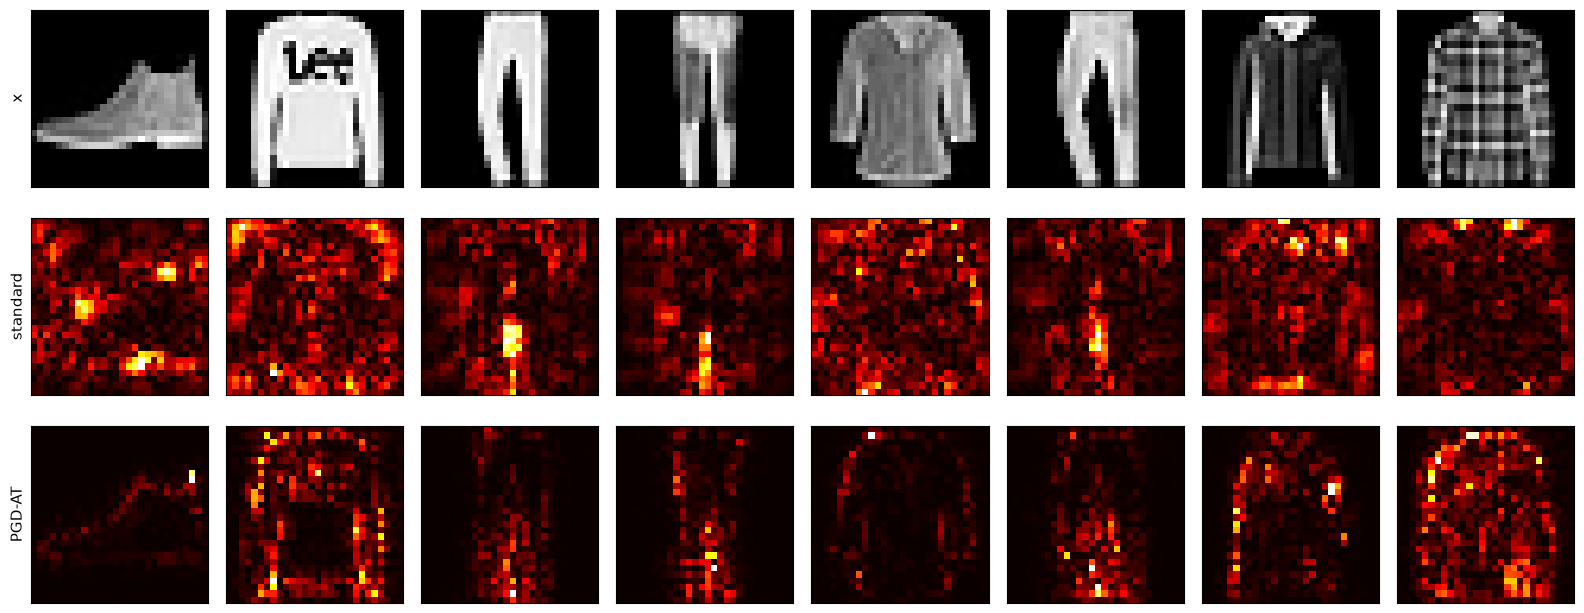

In [38]:
x8, y8 = XF_test[:8], YF_test[:8]
rows = {'x': x8} | {name: input_gradient(m, x8, y8) for name, m in grad_models.items()}
fig, axes = plt.subplots(len(rows), 8, figsize=(16, 2.2 * len(rows)))
for row, (label, images) in enumerate(rows.items()):
    for i in range(8):
        axes[row, i].imshow(images[i, 0].cpu(), cmap='gray' if row == 0 else 'hot')
        axes[row, i].set_xticks([])
        axes[row, i].set_yticks([])
    axes[row, 0].set_ylabel(label, fontsize=11)
plt.tight_layout()
plt.show()

**Вопрос.** Чем отличаются карты моделей — визуально и по доле массы на фоне? Согласуется ли наблюдение с различием PGD accuracy в вашем эксперименте? Почему одной красивой saliency-карты недостаточно для вывода о robustness?

**Ответ.**
У стандартной модели карты более шумные. Заметная чувствительность присутствует на фоне и в отдельных ярких точках. У PGD-AT градиенты сильнее сосредоточены на самом объекте и его контурах. Хотя фон занимает 49.8% пикселей, средняя доля массы градиента на нём составляет 59.55% у стандартной модели и лишь 21.95% у PGD-AT.

Это согласуется с результатами атак. При $\varepsilon=0.1$ диагностическая PGD-20 accuracy составила 1.2% у стандартной модели против 71.5% у PGD-AT. В данном эксперименте более высокая устойчивость сопровождается более выраженной концентрацией saliency на объекте, но это не доказывает причинную связь.

Одной красивой saliency-карты недостаточно. Она показывает локальную чувствительность логита в конкретной точке, а robustness требует сохранения правильного предсказания при допустимых возмущениях вокруг неё. Поэтому устойчивость нужно оценивать сильными атаками с несколькими рестартами. Внешний вид карты служит только дополнительным наблюдением.

### Сохранение результатов обязательной части

Ячейка сохраняет `metrics.json` и три checkpoint в `artifacts/`. Выполняется и в FAST_MODE для проверки формата; при окончательном прогоне файлы перезаписываются с `fast_mode=false`. Сдайте их вместе с ноутбуком. NaN в матрице targeted success записываются как JSON `null`. Checkpoints содержат только `state_dict`, без сериализации объекта модели.

In [74]:
def json_ready(value):
    if isinstance(value, torch.Tensor):
        return json_ready(value.detach().cpu().tolist())
    if isinstance(value, np.ndarray):
        return json_ready(value.tolist())
    if isinstance(value, dict):
        return {str(k): json_ready(v) for k, v in value.items()}
    if isinstance(value, (tuple, list)):
        return [json_ready(v) for v in value]
    if isinstance(value, (float, np.floating)):
        return float(value) if math.isfinite(value) else None
    if isinstance(value, np.integer):
        return int(value)
    return value


artifact_dir = Path('artifacts')
artifact_dir.mkdir(exist_ok=True)
metrics = dict(
    schema_version=2, fast_mode=FAST_MODE, attack_track=ATTACK_TRACK,
    environment=dict(torch=torch.__version__, device=str(device)),
    data=dict(cifar_train=len(X_train), cifar_test=len(X_test),
              fashion_train=len(XF_train), fashion_test=len(XF_test)),
    config=dict(seed=0, cifar_epochs=EPOCHS, ablation_epochs=ABL_EPOCHS,
                cifar_lr=LR, cifar_mean=CIFAR_MEAN, cifar_std=CIFAR_STD,
                fashion_epochs=FM_EPOCHS, at_epochs=AT_EPOCHS, eps_train=EPS_TRAIN),
    cifar=dict(history=history_cifar, ablations=ablation),
    attacks=dict(l2_eps=eps_l2, l2_accuracy=acc_l2, linf_accuracy=acc_linf,
                 selected=S if ATTACK_TRACK == 'targeted' else transfer),
    adversarial=dict(history=at_history, eps=eps_grid, accuracy=robust_curves,
                     sanity=checks, background_share=shares),
    timings=RUN_TIMES,
)
(artifact_dir / 'metrics.json').write_text(json.dumps(json_ready(metrics), ensure_ascii=False, indent=2,
                                                    allow_nan=False), encoding='utf-8')
for name, model in [('resnet20', resnet20), ('fashion_standard', model_a), ('fashion_pgd_at', robust['PGD-7'])]:
    torch.save({k: v.detach().cpu() for k, v in model.state_dict().items()}, artifact_dir / f'{name}.pt')
print('Сохранено:', [p.name for p in sorted(artifact_dir.iterdir())])

Сохранено: ['fashion_pgd_at.pt', 'fashion_standard.pt', 'metrics.json', 'resnet20.pt']


In [75]:
import shutil
from google.colab import files

shutil.make_archive('artifacts', 'zip', 'artifacts')
files.download('artifacts.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

---
# 7\*. Бонусные задачи

## 7.1 Edge of stability (1.5 балла)

Для положительно определённой квадратичной функции GD сходится при $0 < \eta < 2/\lambda_{\max}$, где $\lambda_{\max}$ — наибольшее собственное число гессиана. [Gradient Descent on Neural Networks Typically Occurs at the Edge of Stability](https://arxiv.org/pdf/2103.00065), Cohen et al., 2021: у нейросети sharpness $\lambda_{\max}(\nabla^2 L)$ во время full-batch GD растёт (progressive sharpening), пока не дойдёт до $2/\eta$, и дальше держится около этой границы — loss при этом немонотонный, но продолжает убывать.

1. Реализуйте `hvp(grads, params, v)`: градиент считается один раз с `create_graph=True`, а $Hv$ — VJP градиента с вектором $v$ (`grad_outputs` в `torch.autograd.grad`); гессиан $H$ явно не строится.
2. `top_eigenvalue` ниже — готовый Lanczos с reorthogonalization. Он оценивает **наибольшее algebraic eigenvalue** через наибольшее eigenvalue небольшой tridiagonal matrix. Обычная power iteration для indefinite Hessian может найти отрицательное eigenvalue с наибольшим модулем и здесь не подходит. Менять готовый solver не требуется; проверьте HVP и solver на тестах, включая indefinite quadratic.
3. Full-batch GD (`SGD` без momentum) для MLP с двумя скрытыми слоями по 200 нейронов и tanh на первых 2000 картинках FashionMNIST, loss — MSE по one-hot $\frac12 \|f(x) - e_y\|^2$ (среднее по объектам). Для нескольких $\eta$ записывать loss на каждом шаге и $\lambda_{\max}$ каждые 50 шагов. График: $\lambda_{\max}$ по шагам с горизонталями $2/\eta$.

**Оценивание:** код — 0.7; эксперимент — 0.4; объяснение — 0.4 балла.

In [42]:
if '7.1' in BONUS_TASKS:
    def hvp(grads, params, v):
        grads = torch.autograd.grad(outputs=grads, inputs=params, grad_outputs=v, retain_graph=True,)
        return grads


    def top_eigenvalue(loss_fn, params, iters=20, v=None):
        # Готовый solver: largest algebraic Ritz value, не eigenvalue наибольшего модуля.
        params = list(params)
        sizes = [p.numel() for p in params]
        total = sum(sizes)
        if iters < 1:
            raise ValueError('iters must be positive')
        def unpack(flat):
            return [part.view_as(p) for part, p in zip(flat.split(sizes), params)]
        q = torch.randn(total, device=params[0].device, dtype=params[0].dtype)
        if v is not None:
            # Небольшой шум не даёт warm start застрять в одном инвариантном подпространстве.
            q = torch.cat([vi.detach().flatten() for vi in v]) + 1e-3 * q / q.norm()
        q = q / q.norm()
        grads = torch.autograd.grad(loss_fn(), params, create_graph=True)
        basis, diagonal, off_diagonal = [], [], []
        for k in range(min(iters, total)):
            basis.append(q)
            z = torch.cat([h.detach().flatten() for h in hvp(grads, params, unpack(q))])
            if k:
                z = z - off_diagonal[-1] * basis[-2]
            alpha = torch.dot(q, z)
            diagonal.append(alpha)
            z = z - alpha * q
            Q = torch.stack(basis)
            for _ in range(2):
                z = z - (Q @ z) @ Q
            beta = z.norm()
            if beta.item() < 1e-7 or k + 1 == min(iters, total):
                break
            off_diagonal.append(beta)
            q = z / beta
        T = torch.diag(torch.stack(diagonal))
        if off_diagonal:
            off = torch.stack(off_diagonal)
            T += torch.diag(off, diagonal=1) + torch.diag(off, diagonal=-1)
        # Маленькая eigenproblem на CPU, в том числе при основном обучении на MPS.
        values, vectors = torch.linalg.eigh(T.cpu().double())
        coeffs = vectors[:, -1].to(device=q.device, dtype=q.dtype)
        eigenvector = coeffs @ torch.stack(basis)
        return values[-1].item(), unpack(eigenvector)

In [43]:
if '7.1' in BONUS_TASKS:
    torch.manual_seed(0)
    Q = torch.linalg.qr(torch.randn(30, 30))[0]
    A = Q @ torch.diag(torch.linspace(0.1, 7, 30)) @ Q.T
    w = torch.randn(30, requires_grad=True)
    grads = torch.autograd.grad(0.5 * w @ A @ w, [w], create_graph=True)
    v = torch.randn(30)
    assert torch.allclose(hvp(grads, [w], [v])[0], A @ v, atol=1e-5)

    p = torch.tensor([1.0, -2.0], requires_grad=True)
    lam, _ = top_eigenvalue(lambda: 0.5 * (p[0] ** 2 + 20 * p[1] ** 2), [p], iters=50)
    assert abs(lam - 20) < 1e-3
    lam, _ = top_eigenvalue(lambda: 0.5 * w @ A @ w, [w], iters=300)
    assert abs(lam - 7) < 1e-2
    lam, _ = top_eigenvalue(lambda: 0.5 * (-10 * p[0] ** 2 + 2 * p[1] ** 2), [p], iters=10)
    assert abs(lam - 2) < 1e-4, lam

In [44]:
if '7.1' in BONUS_TASKS:
    N_EOS = 256 if FAST_MODE else 2000
    EOS_STEPS = 100 if FAST_MODE else 3000
    X_eos = XF_train[:N_EOS].flatten(1)
    X_eos = X_eos - X_eos.mean(dim=0)
    Y_eos = F.one_hot(YF_train[:N_EOS], 10).float()


    def make_tanh_mlp(seed=0):
        torch.manual_seed(seed)
        return nn.Sequential(nn.Linear(784, 200), nn.Tanh(), nn.Linear(200, 200), nn.Tanh(), nn.Linear(200, 10)).to(device)


    def mse_loss(model):
        return 0.5 * ((model(X_eos) - Y_eos) ** 2).sum(dim=1).mean()


lr=0.01, stability boundary=200.000
step=   0: loss=0.497282, lambda_max=4.439, lambda_max/(2/lr)=0.022
step= 250: loss=0.262205, lambda_max=5.300, lambda_max/(2/lr)=0.026
step= 500: loss=0.228249, lambda_max=6.330, lambda_max/(2/lr)=0.032
step= 750: loss=0.212655, lambda_max=6.931, lambda_max/(2/lr)=0.035
step=1000: loss=0.202572, lambda_max=7.359, lambda_max/(2/lr)=0.037
step=1250: loss=0.195171, lambda_max=7.737, lambda_max/(2/lr)=0.039
step=1500: loss=0.189349, lambda_max=8.067, lambda_max/(2/lr)=0.040
step=1750: loss=0.184593, lambda_max=8.358, lambda_max/(2/lr)=0.042
step=2000: loss=0.180593, lambda_max=8.623, lambda_max/(2/lr)=0.043
step=2250: loss=0.177142, lambda_max=8.874, lambda_max/(2/lr)=0.044
step=2500: loss=0.174108, lambda_max=9.147, lambda_max/(2/lr)=0.046
step=2750: loss=0.171401, lambda_max=9.576, lambda_max/(2/lr)=0.048
step=3000: loss=0.168957, lambda_max=10.104, lambda_max/(2/lr)=0.051

lr=0.05, stability boundary=40.000
step=   0: loss=0.497282, lambda_max=4.439

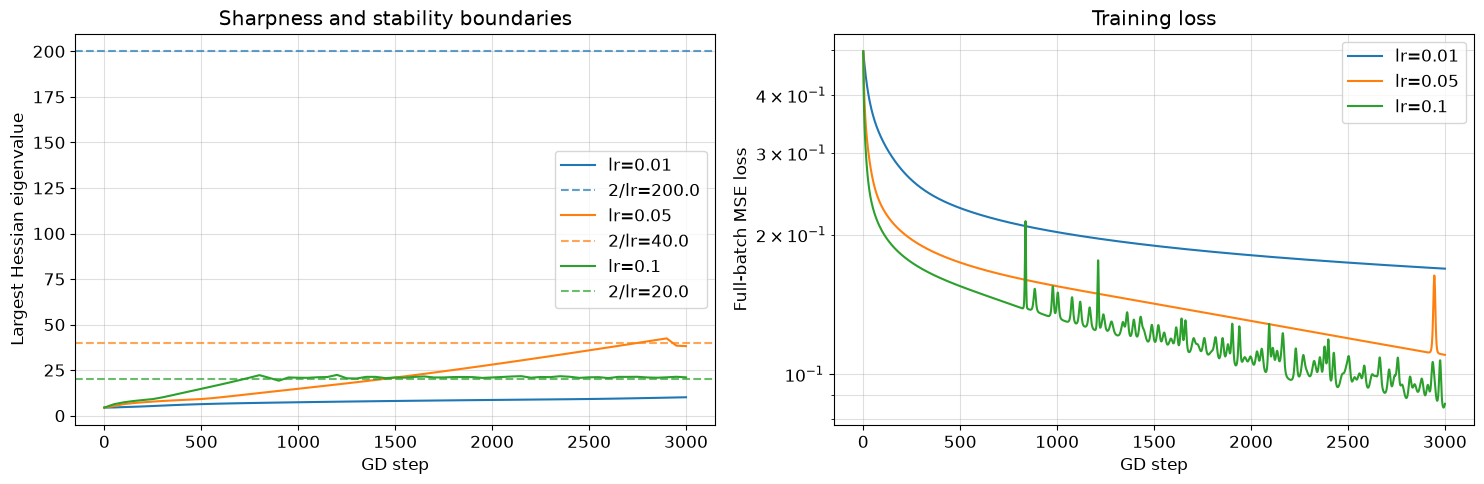


Сводка:
lr=0.01: completed=True, loss_start=0.497282, loss_end=0.168957, last lambda/(2/lr)=0.051, max lambda/(2/lr)=0.051, число увеличений loss=0
lr=0.05: completed=True, loss_start=0.497282, loss_end=0.110112, last lambda/(2/lr)=0.954, max lambda/(2/lr)=1.061, число увеличений loss=28
lr=0.1: completed=True, loss_start=0.497282, loss_end=0.086334, last lambda/(2/lr)=1.052, max lambda/(2/lr)=1.120, число увеличений loss=1036


In [45]:
if '7.1' in BONUS_TASKS:
    EOS_LRS = [0.01, 0.05, 0.1]
    EOS_EVERY = 50
    EOS_LANCZOS_ITERS = 20
    eos_history = {}
    started = time.perf_counter()

    for eta in EOS_LRS:
        # одинаковая начальная модель для каждого learning rate
        set_seed(0)
        model = make_tanh_mlp(seed=0)

        optimizer = torch.optim.SGD(model.parameters(),lr=eta,momentum=0.0,weight_decay=0.0)

        params = list(model.parameters())
        warm_vector = None

        hist = {'loss': [],'sharpness_steps': [],'sharpness': [],'completed': False}

        print(f'\nlr={eta}, stability boundary={2 / eta:.3f}')

        # Шаг 0  до первого обновления
        # Шаг EOS_STEPS после последнего обновления
        for step in range(EOS_STEPS + 1):
            optimizer.zero_grad(set_to_none=True)

            loss = mse_loss(model)
            loss_value = loss.item()
            hist['loss'].append(loss_value)

            if not math.isfinite(loss_value):
                print(
                    f'Прогон остановлен: '
                    f'non-finite loss на шаге {step}.')
                break

            if step % EOS_EVERY == 0:
                sharpness, warm_vector = top_eigenvalue(lambda: mse_loss(model),params,iters=EOS_LANCZOS_ITERS,v=warm_vector)

                warm_vector = [tensor.detach() for tensor in warm_vector]

                hist['sharpness_steps'].append(step)
                hist['sharpness'].append(sharpness)

                if step % 250 == 0 or step == EOS_STEPS:
                    print(
                        f'step={step:4d}: '
                        f'loss={loss_value:.6f}, '
                        f'lambda_max={sharpness:.3f}, '
                        f'lambda_max/(2/lr)='
                        f'{sharpness * eta / 2:.3f}'
                    )

            if step == EOS_STEPS:
                hist['completed'] = True
                break

            loss.backward()
            optimizer.step()

        eos_history[eta] = hist

        del model, optimizer, params, loss, warm_vector

    RUN_TIMES['bonus_eos_seconds'] = (time.perf_counter() - started)

    fig, axes = plt.subplots(1, 2, figsize=(15, 5))

    for eta, hist in eos_history.items():
        line, = axes[0].plot(hist['sharpness_steps'],hist['sharpness'],label=f'lr={eta}')
        axes[0].axhline(2 / eta,linestyle='--',color=line.get_color(),alpha=0.7,label=f'2/lr={2 / eta:.1f}')
        axes[1].semilogy(range(len(hist['loss'])),hist['loss'],label=f'lr={eta}')

    axes[0].set_xlabel('GD step')
    axes[0].set_ylabel('Largest Hessian eigenvalue')
    axes[0].set_title('Sharpness and stability boundaries')

    axes[1].set_xlabel('GD step')
    axes[1].set_ylabel('Full-batch MSE loss')
    axes[1].set_title('Training loss')

    for ax in axes:
        ax.grid(True, which='both', alpha=0.4)
        ax.legend()

    plt.tight_layout()
    plt.show()

    print('\nСводка:')
    for eta, hist in eos_history.items():
        if not hist['sharpness']:
            continue
        ratios = (np.asarray(hist['sharpness']) * eta / 2)

        losses = np.asarray(hist['loss'])
        finite_losses = losses[np.isfinite(losses)]
        increases = int(np.sum(np.diff(finite_losses) > 0))

        print(
            f'lr={eta}: '
            f'completed={hist["completed"]}, '
            f'loss_start={losses[0]:.6f}, '
            f'loss_end={losses[-1]:.6f}, '
            f'last lambda/(2/lr)={ratios[-1]:.3f}, '
            f'max lambda/(2/lr)={ratios.max():.3f}, '
            f'число увеличений loss={increases}'
        )

**Вопрос.** В каких прогонах sharpness приблизилась к $2/\eta$? Если выхода на границу не было, укажите это. Сопоставьте изменения sharpness и loss. Почему локальный критерий для фиксированной положительно определённой квадратичной функции не гарантирует такую же динамику нелинейной сети?

**Ответ.**
При $\eta=0.01$ выхода на границу не было. sharpness выросла с 4.439 до 10.104, оставаясь значительно ниже $2/\eta=200$. Loss плавно снизился с 0.4973 до 0.1690, без увеличений между шагами.

При $\eta=0.05$ sharpness приблизилась к границе $2/\eta=40$. На шаге 2750 она составила 39.942, а максимальное отношение $\lambda_{\max}/(2/\eta)$ достигло 1.061. Около границы появились всплески loss, но в целом он снизился до 0.1101.
При $\eta=0.1$ sharpness достигла границы $2/\eta=20$ примерно к шагу 750 и затем держалась около 20-21, немного превышая её. Loss стал заметно колебаться. Зафиксировано 1036 увеличений, однако общий тренд оставался нисходящим, до 0.0863. Такое поведение согласуется с режимом edge of stability. Локальная граница достигается или слегка превышается, но обучение продолжается.

Для фиксированной положительно определённой квадратичной функции гессиан постоянен, и условие $0<\eta<2/\lambda_{\max}$ обеспечивает сходимость градиентного спуска. У нелинейной сети гессиан и его собственные направления меняются при обновлении весов, а квадратичное приближение верно лишь локально. Поэтому кратковременное превышение границы не обязательно приводит к расходимости, а нахождение ниже неё в одной точке не гарантирует устойчивость всей дальнейшей траектории.

## 7.2 Свёртка через FFT со stride, padding и groups (0.5 балла)

Теорема о свёртке: $\mathcal F(x * w) = \mathcal F(x) \cdot \mathcal F(w)$. Детали:

- DFT считает циклическую свёртку — дополняем нулями до $H + k_h - 1$ по высоте и $W + k_w - 1$ по ширине;
- `F.conv2d` — cross-correlation, поэтому ядро переворачивается;
- сумма по входным каналам остаётся суммой в частотной области; с `groups` — только внутри группы;
- padding — `F.pad` входа; stride $s$ — прореживание «valid»-результата $[\,::s,\; ::s\,]$.

Реализуйте `conv2d_fft` (dilation = 1; stride и padding — целые числа) через `torch.fft.rfft2` / `irfft2` и `einsum`.

**Оценивание:** код — 0.4; эксперимент — 0; объяснение — 0.1 балла.

In [50]:
if '7.2' in BONUS_TASKS:
    def conv2d_fft(x, weight, bias=None, stride=1, padding=0, groups=1):
        B, C_in, _, _ = x.shape
        C_out, _, kh, kw = weight.shape
        x_pad = F.pad(x, (padding, padding, padding, padding))

        H_pad, W_pad = x_pad.shape[-2:]
        # Размер для линейной свёртки
        fft_shape = (H_pad + kh - 1,W_pad + kw - 1)
        x_grouped = x_pad.reshape(B,groups,C_in // groups,H_pad,W_pad,)
        # F.conv2d выполняет cross-correlation
        # Для реализации через свёртку переворачиваем ядро
        w_grouped = weight.flip(-2, -1).reshape(groups,C_out // groups,C_in // groups,kh,kw)
        x_fft = torch.fft.rfft2(x_grouped, s=fft_shape)
        w_fft = torch.fft.rfft2(w_grouped, s=fft_shape)
        out_fft = torch.einsum('bgihw,goihw->bgohw',x_fft,w_fft)
        full = torch.fft.irfft2(out_fft, s=fft_shape)
        # Из полной свёртки выделяем valid-область.
        # Затем выбираем позиции с заданным stride.
        out = full[...,kh - 1:H_pad:stride,kw - 1:W_pad:stride]
        out = out.reshape(B, C_out, out.shape[-2], out.shape[-1])

        if bias is not None:
            out = out + bias[None, :, None, None]

        return out

In [63]:
if '7.2' in BONUS_TASKS:
    torch.manual_seed(0)
    x = torch.randn(2, 4, 13, 10)
    n_checked = 0
    for k, s, p, g in itertools.product([1, 3, (3, 5)], [1, 2, 3], [0, 1, 2], [1, 2, 4]):
        w, b = torch.randn(8, 4 // g, *pair(k)), torch.randn(8)
        ref = F.conv2d(x, w, b, stride=s, padding=p, groups=g)
        out = conv2d_fft(x, w, b, stride=s, padding=p, groups=g)
        assert out.shape == ref.shape and torch.allclose(out, ref, atol=1e-4), (k, s, p, g)
        n_checked += 1
    n_checked

**Вопрос.** Какую долю посчитанных выходов FFT-свёртка выбрасывает при stride $s$? Когда FFT-свёртка всё равно выгоднее прямой?

**Ответ.**
При stride $s$ сохраняется примерно каждый $s$-й выход по высоте и ширине, то есть $1/s^2$ всех рассчитанных valid-выходов. Поэтому выбрасывается примерно $1-1/s^2$. При stride 2 - 75%, при stride 3 - 88.9%. Точная доля зависит от размеров выхода и округления на границах.

FFT-свёртка всё равно может быть выгоднее прямой при больших ядрах и достаточно больших изображениях, когда экономия на вычислении свёртки перекрывает затраты на FFT и расчёт лишних выходов. Большой stride уменьшает это преимущество. Прямая свёртка сразу вычисляет только нужные позиции.

## 7.3 Muon для свёрточных весов (1 балл)

[Muon: An optimizer for hidden layers in neural networks](https://kellerjordan.github.io/posts/muon/), Jordan et al., 2024. Для матричного параметра $W \in \mathbb R^{m \times n}$ с градиентом $G_t$ — так он устроен в `torch.optim.Muon` (momentum через EMA, Nesterov):
$$
B_t = \mu B_{t-1} + (1 - \mu)\, G_t, \qquad U_t = (1 - \mu)\, G_t + \mu B_t, \qquad
W \leftarrow W - \eta \sqrt{\max(1,\, m/n)}\; \mathrm{NS}_5(U_t),
$$
где $\mathrm{NS}_5$ — 5 итераций Ньютона–Шульца, приближающие ортогональный множитель $P Q^\top$ из SVD $U_t = P \Sigma Q^\top$:
$$
X_0 = \frac{U_t}{\|U_t\|_F}, \qquad X_{j+1} = a X_j + b\, (X_j X_j^\top) X_j + c\, (X_j X_j^\top)^2 X_j, \qquad (a, b, c) = (3.4445,\, -4.7750,\, 2.0315)
$$
(если $m > n$, итерации идут для $X^\top$). `torch.optim.Muon` принимает только 2D-параметры, а вес свёртки $(C_{\text{out}}, C_{\text{in}}, k, k)$ — это матрица $C_{\text{out}} \times C_{\text{in}} k^2$ (та же, что в `conv2d_unfold`).

1. Реализуйте `newton_schulz` и `ConvMuon` (без weight decay) для параметров любой размерности $\ge 2$: первая ось — строки, остальные разворачиваются в столбцы. Библиотечный Muon считает итерации в bfloat16, поэтому сравнение с ним — с допуском.
2. Обучите ResNet-20: `ConvMuon` с `MUON_LR` для всех 4D-весов, `MyAdamW` как в `train_cifar` для остального (BN, голова), у обоих cosine schedule, бюджет `EPOCHS`, тот же `set_seed(0)`. Сравните с `history_cifar` из 4.2. Здесь сравниваются два фиксированных training recipe, включая разный weight decay на conv-весах; этот опыт не изолирует влияние одного лишь optimizer и не является общим рейтингом.

**Оценивание:** код — 0.5; эксперимент — 0.3; объяснение — 0.2 балла.

In [66]:
if '7.3' in BONUS_TASKS:
    def newton_schulz(M, steps=5, coeffs=(3.4445, -4.7750, 2.0315)):
        if M.ndim != 2:
            raise ValueError('Expected a 2D matrix')

        original_dtype = M.dtype
        # Низкую точность повышаем для устойчивости операций
        X = (M.float()
            if M.dtype in (torch.float16, torch.bfloat16)
            else M.clone())

        transposed = X.shape[0] > X.shape[1]
        if transposed:
            X = X.T

        X = X / X.norm().clamp_min(1e-7)

        a, b, c = coeffs

        for _ in range(steps):
            A = X @ X.T
            B = b * A + c * (A @ A)
            X = a * X + B @ X

        if transposed:
            X = X.T

        return X.to(dtype=original_dtype)


    class ConvMuon(torch.optim.Optimizer):
        def __init__(self, params, lr=0.02, momentum=0.95):
            super().__init__(params, dict(lr=lr, momentum=momentum))

        @torch.no_grad()
        def step(self):
            for group in self.param_groups:
                mu = group['momentum']
                for p in group['params']:
                    if p.grad is None:
                        continue
                    if p.ndim < 2:
                        raise ValueError('ConvMuon requires parameters with ndim >= 2')

                    grad = p.grad
                    if grad.is_sparse:
                        raise RuntimeError('Sparse gradients are not supported')

                    state = self.state[p]

                    if 'momentum_buffer' not in state:
                        state['momentum_buffer'] = (torch.zeros_like(p))

                    buffer = state['momentum_buffer']

                    # B_t = mu B_{t-1} + (1-mu) G_t
                    buffer.mul_(mu).add_(grad, alpha=1 - mu)
                    # Nesterov: U_t = (1-mu)G_t + mu B_t
                    update = ((1 - mu) * grad + mu * buffer)
                    matrix = update.reshape(p.shape[0], -1)
                    rows, cols = matrix.shape

                    orthogonalized = newton_schulz(matrix)
                    scale = math.sqrt(max(1.0, rows / cols))
                    p.add_(orthogonalized.reshape_as(p),alpha=-group['lr'] * scale)

In [67]:
if '7.3' in BONUS_TASKS:
    def muon_steps(make_optimizer, shape, steps=5):
        torch.manual_seed(0)
        p = torch.randn(shape, requires_grad=True)
        optimizer = make_optimizer(p)
        gen = torch.Generator().manual_seed(1)
        for _ in range(steps):
            optimizer.zero_grad()
            (p * torch.randn(shape, generator=gen)).sum().backward()
            optimizer.step()
        return p.detach()


    torch.manual_seed(0)
    M = torch.randn(64, 32) * torch.logspace(0, -3, 32)
    assert torch.linalg.svdvals(newton_schulz(M)).max() < 1.3

    for shape in [(48, 20), (20, 48)]:
        start = muon_steps(lambda p: torch.optim.SGD([p], lr=0.0), shape)   # lr = 0: начальная точка
        mine = muon_steps(lambda p: ConvMuon([p], lr=0.02), shape)
        ref = muon_steps(lambda p: torch.optim.Muon([p], lr=0.02, weight_decay=0.0), shape)
        assert ((mine - ref).norm() / (ref - start).norm()) < 0.05, shape

    conv_w = muon_steps(lambda p: ConvMuon([p], lr=0.02), (16, 8, 3, 3))
    flat = muon_steps(lambda p: ConvMuon([p], lr=0.02), (16, 72))
    assert torch.allclose(conv_w.view(16, 72), flat, atol=1e-6)

In [68]:
if '7.3' in BONUS_TASKS:
    MUON_LR = 0.02
    set_seed(0)
    resnet_muon = ResNetCIFAR(20).to(device)

    conv_params = [p for p in resnet_muon.parameters() if p.ndim == 4]
    other_decay = [p for p in resnet_muon.parameters() if p.ndim > 1 and p.ndim != 4]
    other_no_decay = [p for p in resnet_muon.parameters() if p.ndim <= 1]

    optimizer_muon = ConvMuon(conv_params, lr=MUON_LR, momentum=0.95)
    optimizer_adamw = MyAdamW([dict(params=other_decay, weight_decay=0.05), dict(params=other_no_decay, weight_decay=0.0)], lr=LR)

    batch_size = 256
    total_steps = EPOCHS * math.ceil(len(X_train) / batch_size)

    scheduler_muon = torch.optim.lr_scheduler.LambdaLR(optimizer_muon, lambda t: cosine_lr(t, total_steps))
    scheduler_adamw = torch.optim.lr_scheduler.LambdaLR(optimizer_adamw, lambda t: cosine_lr(t, total_steps))

    hist_muon = dict(train_loss=[], test_acc=[])
    started = time.perf_counter()

    for epoch in range(EPOCHS):
        resnet_muon.train()
        loss_sum = 0.0
        count = 0

        for x, y in iterate_batches(X_train, Y_train, batch_size, transform=normalize):
            optimizer_muon.zero_grad(set_to_none=True)
            optimizer_adamw.zero_grad(set_to_none=True)

            loss = F.cross_entropy(resnet_muon(x), y)
            loss.backward()

            optimizer_muon.step()
            optimizer_adamw.step()
            scheduler_muon.step()
            scheduler_adamw.step()

            loss_sum += loss.item() * len(y)
            count += len(y)

        epoch_loss = loss_sum / count
        test_acc_muon = accuracy(predict_logits(resnet_muon, X_test, transform=normalize), Y_test)

        hist_muon['train_loss'].append(epoch_loss)
        hist_muon['test_acc'].append(test_acc_muon)

        print(f'Epoch {epoch + 1}/{EPOCHS}: loss={epoch_loss:.4f}, test_acc={test_acc_muon:.4f}')

    RUN_TIMES['bonus_muon_seconds'] = time.perf_counter() - started

    optimizer_muon.zero_grad(set_to_none=True)
    optimizer_adamw.zero_grad(set_to_none=True)
    hist_adamw = history_cifar
    print(f'{"":<10}{"train loss":>12}{"test acc":>10}')
    for name, hist in [('AdamW', hist_adamw), ('Muon', hist_muon)]:
        print(f'{name:<10}{hist["train_loss"][-1]:>12.4f}{hist["test_acc"][-1]:>10.4f}')

Epoch 1/20: loss=1.1408, test_acc=0.6400
Epoch 2/20: loss=0.6641, test_acc=0.7588
Epoch 3/20: loss=0.5034, test_acc=0.7742
Epoch 4/20: loss=0.3995, test_acc=0.8093
Epoch 5/20: loss=0.3194, test_acc=0.8212
Epoch 6/20: loss=0.2471, test_acc=0.8269
Epoch 7/20: loss=0.1834, test_acc=0.8301
Epoch 8/20: loss=0.1303, test_acc=0.8147
Epoch 9/20: loss=0.0930, test_acc=0.8412
Epoch 10/20: loss=0.0637, test_acc=0.8347
Epoch 11/20: loss=0.0428, test_acc=0.8383
Epoch 12/20: loss=0.0284, test_acc=0.8418
Epoch 13/20: loss=0.0175, test_acc=0.8475
Epoch 14/20: loss=0.0108, test_acc=0.8461
Epoch 15/20: loss=0.0060, test_acc=0.8482
Epoch 16/20: loss=0.0031, test_acc=0.8516
Epoch 17/20: loss=0.0017, test_acc=0.8494
Epoch 18/20: loss=0.0011, test_acc=0.8522
Epoch 19/20: loss=0.0008, test_acc=0.8538
Epoch 20/20: loss=0.0007, test_acc=0.8543
            train loss  test acc
AdamW           0.0108    0.8265
Muon            0.0007    0.8543


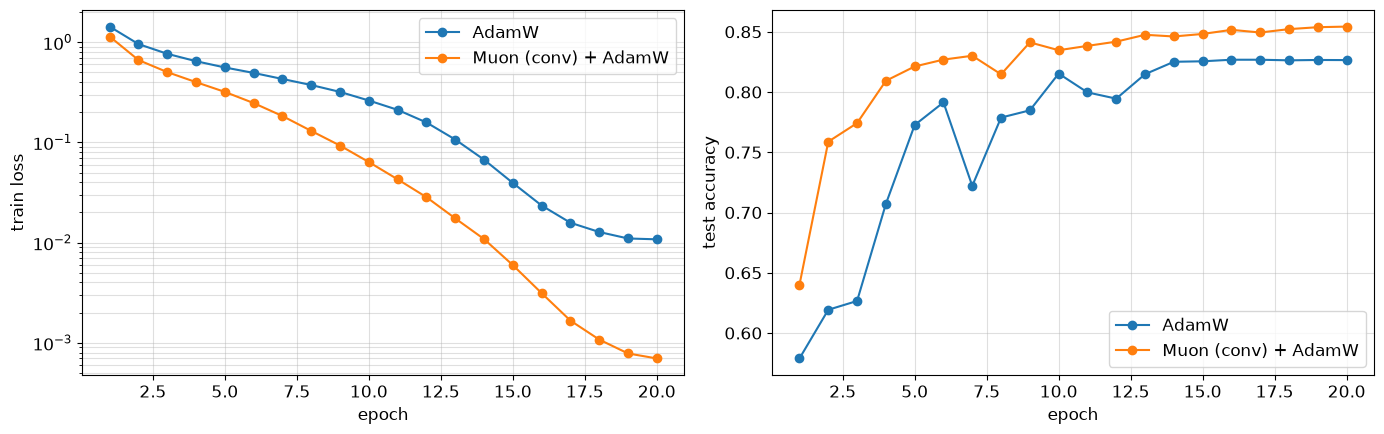

In [69]:
if '7.3' in BONUS_TASKS:
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))
    for name, hist in [('AdamW', hist_adamw), ('Muon (conv) + AdamW', hist_muon)]:
        epochs_axis = range(1, len(hist['test_acc']) + 1)
        ax1.semilogy(epochs_axis, hist['train_loss'], 'o-', label=name)
        ax2.plot(epochs_axis, hist['test_acc'], 'o-', label=name)
    ax1.set_ylabel('train loss')
    ax2.set_ylabel('test accuracy')
    for ax in (ax1, ax2):
        ax.set_xlabel('epoch')
        ax.grid(True, which='both', alpha=0.4)
        ax.legend()
    plt.tight_layout()
    plt.show()

**Вопрос.** Какой оптимизатор быстрее снижает train loss и какой даёт лучшую test accuracy при том же бюджете? Сколько памяти состояния на параметр у каждого?

**Ответ.**
В моём эксперименте Muon для свёрточных весов + AdamW для остальных параметров быстрее снижает train loss: после 20 эпох он равен 0.0007, тогда как у AdamW 0.0108. Финальная test accuracy также выше: 85.43% против 82.65%, преимущество составляет 2.78 процентного пункта. Это сравнение при одинаковом числе эпох.

AdamW хранит два значения состояния на каждый скалярный параметр: первый и второй моменты градиента, то есть примерно 8 байт при float32.

ConvMuon хранит один momentum-буфер: примерно 4 байта на параметр. В смешанной схеме свёрточные веса требуют одного буфера, остальные параметры двух. Здесь не учитываются сами веса, градиенты и временные тензоры вычислений.

## 7.4 $L_0$-атака на $L_\infty$-робастную модель (1 балл)

Ограничение — число изменённых пикселей:
$$
\max_{\|\delta\|_0 \le k,\;\; x + \delta \in [0, 1]^d} L\big(f(x + \delta), y\big).
$$
Линеаризация: пиксель $i$ выгоднее всего довести до 0 или до 1, прирост loss
$$
\mathrm{gain}_i = \max\big(g_i (1 - x_i),\; -g_i\, x_i\big), \qquad g = \nabla_x L.
$$
Жадная атака: $k$ раз пересчитать градиент и изменить ещё не тронутый пиксель с максимальным $\mathrm{gain}_i$ — на 1, если $g_i > 0$, иначе на 0.

1. Используйте готовую `greedy_pixel_attack` из семинара 4 ниже; переписывать её не требуется. Баллы — за эксперимент и интерпретацию.
2. Accuracy от $k$ для стандартной модели и PGD-AT на `XF_test[:500]`.

**Оценивание:** код — 0; эксперимент — 0.5; объяснение — 0.5 балла.

In [76]:
if '7.4' in BONUS_TASKS:
    def greedy_pixel_attack(model, x, y, k):
        x_adv = x.detach().clone()
        changed = torch.zeros_like(x_adv, dtype=torch.bool)
        for _ in range(k):
            x_adv.requires_grad_(True)
            with torch.enable_grad():
                grad, = torch.autograd.grad(F.cross_entropy(model(x_adv), y, reduction='sum'), x_adv)
            x_adv = x_adv.detach()
            gain = torch.maximum(grad * (1 - x_adv), -grad * x_adv).masked_fill(changed, -float('inf'))
            idx = gain.flatten(1).argmax(dim=1, keepdim=True)
            new_val = (grad.flatten(1).gather(1, idx) > 0).float()
            x_adv = x_adv.flatten(1).scatter(1, idx, new_val).view_as(x)
            changed = changed.flatten(1).scatter(1, idx, True).view_as(x)
        return x_adv

In [77]:
if '7.4' in BONUS_TASKS:
    x, y = XF_test[:500], YF_test[:500]
    x5 = greedy_pixel_attack(model_a, x, y, k=5)
    n_changed = ((x5 - x).flatten(1) != 0).sum(dim=1)
    assert n_changed.max() <= 5 and x5.min() >= 0 and x5.max() <= 1
    assert torch.isin(x5[x5 != x], torch.tensor([0.0, 1.0], device=x.device)).all()
    assert_no_param_grads(model_a)
    print({'clean': attack_accuracy(model_a, x, y), 'L0, k=5': attack_accuracy(model_a, x5, y)})

    ks = [0, 1, 2, 3, 5, 10, 20, 30]
    l0_curves = {name: [attack_accuracy(m, greedy_pixel_attack(m, x, y, k), y) for k in ks]
                 for name, m in [('standard', model_a), ('PGD-AT', robust['PGD-7'])]}
    for name, accs in l0_curves.items():
        print(f'{name:<10}' + ''.join(f'{a:>7.3f}' for a in accs))

{'clean': 0.922, 'L0, k=5': 0.64}
standard    0.922  0.898  0.848  0.782  0.640  0.386  0.140  0.026
PGD-AT      0.838  0.810  0.790  0.770  0.716  0.608  0.416  0.308


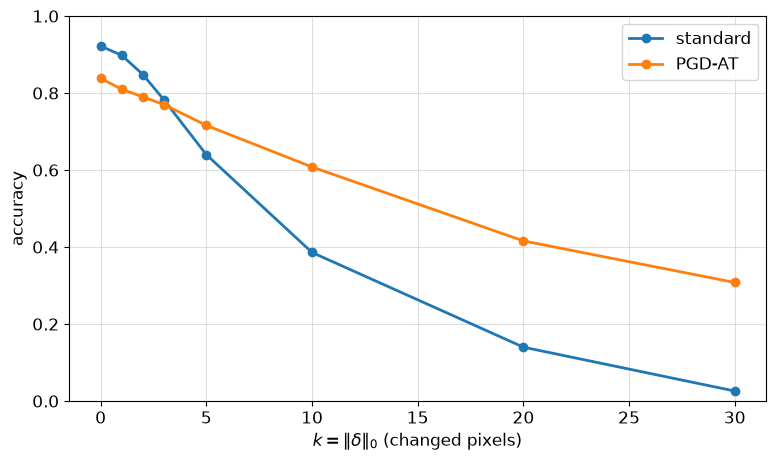

In [78]:
if '7.4' in BONUS_TASKS:
    plt.figure(figsize=(9, 5))
    for name, accs in l0_curves.items():
        plt.plot(ks, accs, 'o-', linewidth=2, label=name)
    plt.xlabel(r'$k = \|\delta\|_0$ (changed pixels)')
    plt.ylabel('accuracy')
    plt.ylim(0, 1)
    plt.legend()
    plt.grid(True, alpha=0.4)
    plt.show()

**Вопрос.** Помогает ли робастность в $L_\infty$ против $L_0$-атаки? Почему $L_\infty$-шар радиуса $\varepsilon$ не защищает от изменения одного пикселя с 0 до 1?

**Ответ.**
В моём эксперименте робастность в $L_\infty$ частично помогает против $L_0$-атаки. При изменении 5 пикселей accuracy PGD-AT составляет 71.6% против 64.0% у стандартной модели, при 10 - 60.8% против 38.6%, при 30 - 30.8% против 2.6%. Однако при $k=0,1,2,3$ стандартная модель сохраняет более высокую accuracy благодаря лучшему исходному качеству. Таким образом, преимущество PGD-AT заметно при более сильной атаке, но полной защиты нет.

Ограничения норм различаются. $L_0$ ограничивает число изменённых пикселей, а $L_\infty$ максимальную величину изменения каждого пикселя. Если один пиксель изменить с 0 до 1, то $\|\delta\|_0=1$, но $\|\delta\|_\infty=1$. Такое возмущение выходит за пределы $L_\infty$-шара обучающего радиуса $\varepsilon=0.1$, поэтому устойчивость внутри этого шара на него не распространяется.

## 7.5 Catastrophic overfitting (1 балл)

Включается через `'7.5'` в `BONUS_TASKS`; нужны функции из 6.1 и 6.2. Обучите две дополнительные модели с готовыми FGSM и FGSM-RS при `EPS_CO=0.2`. FGSM-RS начинает из случайной точки, делает один шаг размера $1.25\varepsilon$ и проецируется обратно в допустимое множество.

В работе [Wong et al., 2020](https://arxiv.org/pdf/2001.03994) описано catastrophic overfitting: PGD accuracy резко падает, хотя FGSM accuracy остаётся высокой. Random start может помочь, но ни возникновение эффекта за наш бюджет, ни его устранение не гарантированы.

Код обучения и графика дан; баллы — за диагностику и объяснение. Не меняйте эпохи или радиус только ради получения «нужной картинки». Если добавите контрольный опыт, запишите его настройки отдельно.

**Оценивание:** код — 0; эксперимент — 0.5; объяснение — 0.5 балла.

In [ ]:
if '7.5' in BONUS_TASKS:
    EPS_CO = 0.2
    co_history = {}
    for name in ['FGSM', 'FGSM-RS']:
        print(name)
        set_seed(0)
        robust[f'{name}, eps={EPS_CO}'] = SmallCNN()
        co_history[name] = adversarial_train(robust[f'{name}, eps={EPS_CO}'], EPS_CO, TRAIN_ATTACKS[name])

In [ ]:
if '7.5' in BONUS_TASKS:
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
    for ax, (name, hist) in zip(axes, co_history.items()):
        epochs_axis = range(1, len(hist['clean']) + 1)
        for key, label in [('clean', 'clean'), ('fgsm', 'FGSM'), ('pgd', 'PGD-20')]:
            ax.plot(epochs_axis, hist[key], 'o-', linewidth=2, label=label)
        ax.set_title(f'{name}-AT, eps = {EPS_CO}')
        ax.set_xlabel('epoch')
        ax.grid(True, alpha=0.4)
    axes[0].set_ylabel('accuracy')
    axes[0].set_ylim(0, 1)
    axes[1].legend()
    plt.tight_layout()
    plt.show()

In [ ]:
if '7.5' in BONUS_TASKS:
    co_checks = {name: sanity_checks(robust[f'{name}, eps={EPS_CO}'], XF_test[:N_SANITY], YF_test[:N_SANITY], EPS_CO)
                 for name in ['FGSM', 'FGSM-RS']}
    print(co_checks)

**Вопрос.** Был ли резкий спад PGD accuracy и на какой эпохе? Изменил ли картину random start? Сопоставьте динамику FGSM/PGD и результаты усиленной атаки. Если catastrophic overfitting не наблюдается, укажите это и предложите одну проверяемую гипотезу о том, от чего он мог бы зависеть.

**Ответ.**